# Environment-dependent tropical-cyclone genesis rate
## 1° gridded Poisson model interpreted as a discretized inhomogeneous Poisson point process

This notebook builds a first-generation replacement for:

**phase-conditioned basin frequency → month sampling → empirical/GPI genesis map**

with one fitted environmental rate surface:

\[
N_{iym}\sim \mathrm{Poisson}(\mu_{iym}),\qquad
\mu_{iym}=E_{iym}\lambda_{iym}
\]

and

\[
\log \lambda_{iym}
=
\alpha
+\mathrm{month\ effect}
+\beta_{PI}PI
+\beta_{RH}RH
+\beta_{VWS}VWS
+\beta_{\eta}\eta.
\]

Here \(i\) is a 1° genesis cell, \(y\) the year and \(m\) the month.

The exposure \(E\) explicitly accounts for:

- spherical cell area;
- the fraction of the cell that is eligible ocean;
- month duration.

The fitted expected cell counts \(\mu_i\) simultaneously determine:

1. basin/month storm frequency: \(\Lambda=\sum_i\mu_i\);
2. genesis-location probabilities: \(p_i=\mu_i/\Lambda\).

After a 1° cell is selected, the exact genesis location is sampled uniformly over the **eligible ocean part** of the cell using a 0.1° fine mask. This keeps the downscaling deliberately simple while preventing land genesis.

## 0. Assumptions and inputs

This notebook deliberately starts with one basin (e.g. North Atlantic) and one simple Poisson specification.

Expected inputs:

1. `env_native`: monthly `xarray.Dataset` containing at least:
   - `pi` : thermodynamic potential intensity [m/s]
   - `rh600` : relative humidity at 600 hPa [% or fraction, but consistent]
   - `vws` : 850–200 hPa vertical wind shear magnitude [m/s]
   - `abs_vort850` : absolute vorticity magnitude [s-1]

2. `genesis`: a pandas DataFrame with one row per historical genesis event:
   - `storm_id`
   - `time`
   - `lat`
   - `lon`

The genesis definition must match the simulator target. If the simulator starts storms when they first reach tropical-storm intensity, use that same definition here.

3. `land_gdf`: a reasonably high-resolution land polygon GeoDataFrame (Natural Earth 10m / GSHHG / existing project coastline).

4. `basin_polygon`: the valid basin-water domain. This is important because `~land` alone can leave inland water bodies eligible.

In [1]:
from __future__ import annotations

import calendar
import os
import sys
from pathlib import Path
from dataclasses import dataclass

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import geopandas as gpd
from shapely import box, contains_xy, union_all

import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy.stats import poisson
import os
from datetime import date

## 1. Configuration

In [2]:
# Set this to the repository root. The notebook assumes the normal project layout:
# REPO_ROOT/
#   CODE/genesis_matrix.py
#   Land_ocean_masks/Land_ocean_mask_NA.txt
REPO_ROOT = os.path.dirname(os.getcwd())
sys.path.append(str(Path.cwd().parent))


import CODE.genesis_matrix as gm

# genesis_matrix.py currently derives __location__ from os.getcwd().
# Explicitly point it at the repository root so its existing mask loader is robust
# even if this notebook was launched from another directory.
gm.__location__ = str(REPO_ROOT)


ACTIVE_MONTHS = {
    "EP": (6, 7, 8, 9, 10, 11),
    "NA": (6, 7, 8, 9, 10, 11),
    "NI": (4, 5, 6, 9, 10, 11),
    "SI": (1, 2, 3, 4, 11, 12),
    "SP": (1, 2, 3, 4, 11, 12),
    "WP": (5, 6, 7, 8, 9, 10, 11),
}


@dataclass(frozen=True)
class GenesisConfig:
    basin: str = "WP"

    # Exposure scaling only changes the intercept and keeps coefficients readable.
    area_unit_km2: float = 100_000.0
    reference_month_days: float = 365.2425 / 12.0

    # Strict temporal holdout for the first experiment.
    first_test_year: int = 2016

    # Same native mask resolution already used by STORM.
    fine_res: float = 0.1

    active_months: tuple = (5, 6, 7, 8, 9, 10, 11)
    lat_min, lat_max, lon_min, lon_max = gm.BOUNDARIES_BASINS("WP")


CFG = GenesisConfig()

lat0, lat1, lon0, lon1 = gm.BOUNDARIES_BASINS(CFG.basin)
ROWS = int(abs(lat1 - lat0))
COLS = int(abs(lon1 - lon0))

LAT2D, LON2D = gm.basin_cell_centers(CFG.basin, ROWS, COLS)
LAT = LAT2D[:, 0]  # north -> south, matching genesis_matrix.py
LON = LON2D[0, :]  # west -> east, 0..360 convention

print(CFG)
print(f"{CFG.basin}: {ROWS} x {COLS} 1-degree cells")
print(f"lat: {LAT[0]} -> {LAT[-1]}")
print(f"lon: {LON[0]} -> {LON[-1]}")

MDR_REGION = {"lat_min" : 10,
              "lat_max" : 20,
              "lon_min" : 110,
              "lon_max" : 160}


TROPICS_REGION = {"lat_min" : -30,
              "lat_max" : 30,
              "lon_min" : 0,
              "lon_max" : 360}

GenesisConfig(basin='WP', area_unit_km2=100000.0, reference_month_days=30.436875, first_test_year=2016, fine_res=0.1, active_months=(5, 6, 7, 8, 9, 10, 11))
WP: 55 x 80 1-degree cells
lat: 59.5 -> 5.5
lon: 100.5 -> 179.5


### Get mask

In [3]:
import pandas as pd
import geopandas
import matplotlib.pyplot as plt
from geodatasets import get_path


land_gdf = geopandas.read_file(get_path("naturalearth.land"))

### Load STORMS

In [4]:
REPO_ROOT = os.path.dirname(os.getcwd())

year = np.load(os.path.join(REPO_ROOT, "YEARLIST_INTERP.npy"), allow_pickle=True).item()
lat = np.load(os.path.join(REPO_ROOT, "LATLIST_INTERP.npy"), allow_pickle=True).item()
lon = np.load(os.path.join(REPO_ROOT, "LONLIST_INTERP.npy"), allow_pickle=True).item()
pressure = np.load(os.path.join(REPO_ROOT, "PRESLIST_INTERP.npy"), allow_pickle=True).item()
month = np.load(os.path.join(REPO_ROOT, "MONTHLIST_INTERP.npy"), allow_pickle=True).item()
speed = np.load(
    os.path.join(REPO_ROOT, "WINDLIST_INTERP.npy"), allow_pickle=True
).item()

idx_clean = [idx for idx, i in enumerate(lat) if len(lat[i]) > 0]
year = [year[i] for i in idx_clean]
month = [month[i] for i in idx_clean]
lat = [lat[i] for i in idx_clean]
lon = [lon[i] for i in idx_clean]
pressure = [pressure[i] for i in idx_clean]
speed = [speed[i] for i in idx_clean]


In [5]:
genesis = pd.DataFrame(
    {
        "stormid": idx_clean,
        "time": [date(int(year[i][0]), int(month[i][0]), 1) for i in range(len(idx_clean))],
        "latitude": [lat_i[0] for lat_i in lat],
        "longitude": [lon_i[0] for lon_i in lon],
        "speed": [speed_i[0] for speed_i in speed],
    }
)

In [6]:
genesis_wp = genesis.loc[(genesis["latitude"] > 0) & (genesis["longitude"] < 200),]

### Load npy files

In [157]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr


path_files = Path(
    "/home/mbaldacchino/data/SIENA-IH-STORM_1980_2025_VF/SIENA-IH-STORM/env_yearly"
)

# Files we actually need for the first genesis model.
NAME_MAP = {
    "VMAX_PI": "pi",
    "VWS": "vws",
    "RH600": "rh600",
    "VORT850": "vort850",
    "SST": "sst",
    # Adapt the left-hand names to your actual .npy filenames:
    # "T2M": "t2m",
    "MSLP": "mslp",
    #"U850": "u850",
}

NAME_MODEL = {
    "VMAX_PI": "pi",  # thermodynamic PI maximum wind [m/s]
    "VWS": "vws",  # 850-200 hPa shear [m/s]
    "RH600": "rh600",  # relative humidity
    "ETA850": "eta850",  # absolute vorticity capped [s-1]
    "W500": "w500",  # vertical velocity at 500hPa
}

START_YEAR = 1980
END_YEAR = 2024


def parse_env_filename(path):
    """
    Parse:
        VWS_2000_6.npy
        VMAX_PI_2000_6.npy
        VORT850_2018_10.npy

    Returns:
        variable, year, month
    """
    name, year, month = path.stem.rsplit("_", 2)

    return name, int(year), int(month)

def load_environment_dataset(
    path_files,
    name_map,
    start_year=1980,
    end_year=2024,
):
    path_files = Path(path_files)

    # Your arrays are the global 0.25° fields used elsewhere in the repo:
    # 721 latitudes: 90 -> -90
    # 1440 longitudes: 0 -> 359.75
    lat = np.linspace(90.0, -90.0, 721)
    lon = np.arange(1440) * 0.25

    variables = {}

    for file_name, xr_name in name_map.items():
        records = []

        for file in path_files.glob(f"{file_name}_*.npy"):
            name, year, month = parse_env_filename(file)

            if name != file_name:
                continue

            if not (start_year <= year <= end_year):
                continue

            records.append((year, month, file))

        records.sort(key=lambda x: (x[0], x[1]))

        if not records:
            raise FileNotFoundError(f"No files found for {file_name}")

        arrays = []
        times = []

        for year, month, file in records:
            arr = np.load(file)

            if arr.shape != (721, 1440):
                raise ValueError(f"{file.name}: expected (721, 1440), got {arr.shape}")

            arrays.append(arr)

            times.append(pd.Timestamp(year=year, month=month, day=1))

        variables[xr_name] = xr.DataArray(
            np.stack(arrays, axis=0),
            dims=("valid_time", "latitude", "longitude"),
            coords={
                "valid_time": pd.DatetimeIndex(times),
                "latitude": lat,
                "longitude": lon,
            },
            name=xr_name,
        )

    return xr.Dataset(variables)

env_native = load_environment_dataset(
    path_files=path_files,
    name_map=NAME_MAP,
    start_year=START_YEAR,
    end_year=END_YEAR,
)

OMEGA = 7.2921e-5

f = 2 * OMEGA * np.sin(np.deg2rad(env_native.latitude))

eta = env_native["vort850"] + f

env_native["eta850"] = xr.where(
    eta > 0,
    eta,
    0.0,
).clip(max=5e-5)

# TEMP FIX ADD W500
vv = xr.open_dataset("/home/mbaldacchino/data/vertical_velocity.grib")
vv = vv.rename_vars({"w": "w500"})

env_native = env_native.merge(
    vv.swap_dims({"time": "valid_time"})
    .sel(valid_time=slice("1980-01-01", "2025-12-01"))
    .drop_vars(["number", "time", "step"])
)

del vv

/home/mbaldacchino/miniconda/envs/cat/lib/python3.13/site-packages/cfgrib/xarray_plugin.py:131: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely on the presence of a timedelta64 dtype attribute, which is now xarray's default way of encoding timedelta64 values. To continue decoding timedeltas based on the presence of a timedelta-like units attribute, users will need to explicitly opt-in by passing True or CFTimedeltaCoder(decode_via_units=True) to decode_timedelta. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  vars, attrs, coord_names = xr.conventions.decode_cf_variables(


In [158]:
import numpy as np
import pandas as pd
import xarray as xr

# ============================================================
# 1. CONFIGURATION - IMPORTANT - Carry the  XX years before for window
# ============================================================

START_YEAR = 1980
END_YEAR = 2024

CLIM_WINDOW = 40

# The SST DataArray must cover at least 1940–2024
# if START_YEAR = 1980 and CLIM_WINDOW = 40.
#
# Expected:
# dims = (valid_time, latitude, longitude)
# longitude convention = 0–360
# one value per calendar month


# sst_full = env_native["sst"]
sst_full = xr.open_dataset("/home/mbaldacchino/data/sst_1940_2026.nc")["sst"]


# EIO: East Indian Ocean
EIO = {
    "lat_min": -10,
    "lat_max": 22.5,
    "lon_min": 75,
    "lon_max": 100,
}

# SWP: Southwest Pacific
SWP = {
    "lat_min": -40,
    "lat_max": -20,
    "lon_min": 160,
    "lon_max": 190,  # 170°W
}

# WWP: Western Pacific Warm Pool
WWP = {
    "lat_min": 0,
    "lat_max": 16,
    "lon_min": 125,
    "lon_max": 165,
}


# ============================================================
# 2. SPATIAL PROCESSING
# ============================================================

def spatial_mask(da, boxes):
    """Union of one or more geographic boxes."""

    mask = xr.zeros_like(
        da.isel(valid_time=0, drop=True),
        dtype=bool,
    )

    for box in boxes:
        m = (
            (da.latitude >= box["lat_min"])
            & (da.latitude <= box["lat_max"])
            & (da.longitude >= box["lon_min"])
            & (da.longitude <= box["lon_max"])
        )

        mask = mask | m

    return mask


def regional_area_mean(da, boxes):
    """
    Area-weighted monthly mean over the union of boxes.

    Crops the DataArray before applying the spatial mask
    to avoid unnecessary operations on the global grid.
    """

    lat_min = min(b["lat_min"] for b in boxes)
    lat_max = max(b["lat_max"] for b in boxes)

    lon_min = min(b["lon_min"] for b in boxes)
    lon_max = max(b["lon_max"] for b in boxes)

    # Handle either ascending or descending latitude
    descending = (
        da.latitude.values[0] > da.latitude.values[-1]
    )

    lat_slice = (
        slice(lat_max, lat_min)
        if descending
        else slice(lat_min, lat_max)
    )

    sub = da.sel(
        latitude=lat_slice,
        longitude=slice(lon_min, lon_max),
    )

    if sub.latitude.size == 0 or sub.longitude.size == 0:
        raise ValueError(
            f"Empty spatial selection: {boxes}"
        )

    mask = spatial_mask(sub, boxes)

    sub = sub.where(mask)

    weights = np.cos(np.deg2rad(sub.latitude))

    return sub.weighted(weights).mean(
        ["latitude", "longitude"],
        skipna=True,
    )


# ============================================================
# 3. ROLLING CLIMATOLOGY
# ============================================================

def rolling_monthly_ssta(
    monthly_sst: pd.Series,
    window: int = 40,
) -> pd.DataFrame:
    """
    Compute monthly SST anomalies using a trailing
    climatology of `window` complete calendar years.

    For target year Y and calendar month M:

        C(Y,M) = mean[SST(Y-40,M), ..., SST(Y-1,M)]

        SSTA(Y,M) = SST(Y,M) - C(Y,M)

    The target year is excluded.

    Missing historical months invalidate the corresponding
    reference window rather than silently shortening it.
    """

    s = monthly_sst.copy().sort_index()

    # Normalize all timestamps to the first day of their month
    s.index = (
        pd.DatetimeIndex(s.index)
        .to_period("M")
        .to_timestamp()
    )

    if s.index.has_duplicates:
        raise ValueError(
            "Multiple SST observations for the same calendar month."
        )

    # Ensure missing calendar months are explicitly represented
    s = s.asfreq("MS")

    climatology = (
        s.groupby(s.index.month)
        .transform(
            lambda x: (
                x.shift(1)
                .rolling(
                    window=window,
                    min_periods=window,
                )
                .mean()
            )
        )
    )

    return pd.DataFrame(
        {
            "sst": s,
            "climatology": climatology,
            "ssta": s - climatology,
        }
    )


# ============================================================
# 4. SEASONAL AGGREGATION
# ============================================================

def seasonal_index(
    monthly_series: pd.Series,
    months: list[int],
) -> pd.Series:
    """
    Calculate yearly means over the selected calendar months.

    A yearly value is only returned if every requested
    month is available and non-missing.

    Monthly values receive equal weights.
    """

    selected = monthly_series.loc[
        monthly_series.index.month.isin(months)
    ]

    grouped = selected.groupby(selected.index.year)

    seasonal = grouped.mean()

    # Require a complete period
    seasonal = seasonal.where(
        grouped.count() == len(months)
    )

    seasonal.index.name = "year"

    return seasonal


# ============================================================
# 5. EXTRACT REGIONAL SST TIME SERIES
# ============================================================

# Spatial aggregation is performed only once for each region.

monthly_sst = pd.DataFrame(
    {
        "eio": regional_area_mean(
            sst_full, [EIO]
        ).to_series(),

        "swp": regional_area_mean(
            sst_full, [SWP]
        ).to_series(),

        "wwp": regional_area_mean(
            sst_full, [WWP]
        ).to_series(),
    }
).sort_index()


# ============================================================
# 6. COMPUTE MONTHLY ANOMALIES
# ============================================================

rolling_results = {
    name: rolling_monthly_ssta(
        monthly_sst[name],
        window=CLIM_WINDOW,
    )
    for name in ["eio", "swp", "wwp"]
}

monthly_ssta = pd.DataFrame(
    {
        name: result["ssta"]
        for name, result in rolling_results.items()
    }
)

# SST gradient anomaly:
# Southwest Pacific - Western Pacific Warm Pool

monthly_ssta["sstg"] = (
    monthly_ssta["swp"]
    - monthly_ssta["wwp"]
)


# ============================================================
# 7. COMPUTE THE TWO WNP INDICES
# ============================================================

# Original Zhan et al. definitions:
#
# EIO  = June–August mean EIO SSTA
# SSTG = March–May mean (SWP SSTA - WWP SSTA)

eio_jja = seasonal_index(
    monthly_ssta["eio"],
    months=[6, 7, 8],
)

sstg_mam = seasonal_index(
    monthly_ssta["sstg"],
    months=[3, 4, 5],
)


# ============================================================
# 8. CONSTRUCT YEARLY DATAFRAME
# ============================================================

years = np.arange(
    START_YEAR,
    END_YEAR + 1,
)

wnp_predictors = pd.DataFrame(
    {"year": years}
)

wnp_predictors["eio"] = (
    wnp_predictors["year"].map(eio_jja)
)

wnp_predictors["sstg"] = (
    wnp_predictors["year"].map(sstg_mam)
)

# New experiment: contemporaneous JJA SST gradient

sstg_jja = seasonal_index(
    monthly_ssta["sstg"],
    months=[6, 7, 8],
)

wnp_predictors["sstg_jja"] = wnp_predictors["year"].map(sstg_jja)


# ============================================================
# 9. CHECK HISTORICAL COVERAGE
# ============================================================

missing = wnp_predictors.loc[
    wnp_predictors[["eio", "sstg"]]
    .isna()
    .any(axis=1),
    "year",
].tolist()

if missing:
    raise ValueError(
        "Incomplete EIO/SSTG indices for years "
        f"{missing}.\n"
        f"A strict {CLIM_WINDOW}-year trailing climatology "
        f"requires monthly SST history beginning no later "
        f"than {START_YEAR - CLIM_WINDOW}. "
        "Check historical data coverage and missing months."
    )

print(wnp_predictors.head())
print(wnp_predictors.tail())
env_native = env_native.drop_vars(["sst"])

   year       eio      sstg  sstg_jja
0  1980  0.378988 -0.076439 -0.416810
1  1981  0.116063  0.128697 -0.326588
2  1982  0.133736 -0.298411  0.018320
3  1983  0.540874  0.496022  0.047885
4  1984 -0.199605 -0.245600 -0.092692
    year       eio      sstg  sstg_jja
40  2020  0.504360  0.063638 -0.032269
41  2021  0.299482 -0.290247 -0.044589
42  2022  0.153690  0.579415  0.597832
43  2023  0.330905 -0.084271  0.000245
44  2024  0.698885 -0.023111 -0.265099


In [160]:
eio_raw = seasonal_index(
    monthly_sst["eio"],
    [6, 7, 8],
)

sstg_raw = seasonal_index(
    monthly_sst["swp"] - monthly_sst["wwp"],
    [3, 4, 5],
)



eio_monthly = (
    regional_area_mean(
        sst_full,
        [EIO],
    )
    .to_series()
    .sort_index()
)

# Example using a monthly climatology estimated on training data
train_eio = eio_monthly#[eio_monthly.index.year <= CFG.last_train_year]

monthly_clim = train_eio.groupby(train_eio.index.month).mean()

eio_anom = pd.Series(
    [value - monthly_clim.loc[t.month] for t, value in eio_monthly.items()],
    index=eio_monthly.index,
    name="eio_anom",
)

# Causal 3-month state: current + previous two months
eio_dynamic = eio_anom.rolling(3, min_periods=3).mean()


eio_dynamic_df = eio_dynamic.rename("eio_dynamic").reset_index()

eio_dynamic_df["year"] = eio_dynamic_df["valid_time"].dt.year

eio_dynamic_df["month"] = eio_dynamic_df["valid_time"].dt.month

eio_dynamic_df = eio_dynamic_df[["year", "month", "eio_dynamic"]]

## 2. Grid definition and exact spherical cell areas

A 1° latitude-longitude cell does not have the same area at 10°N and 50°N.
The exposure therefore uses spherical rectangle area rather than a constant cell area.

In [10]:
EARTH_RADIUS_KM = 6371.0088


def spherical_1deg_area_km2(lat_center):
    """Exact spherical area of a 1° x 1° lat/lon cell centered at lat_center."""
    lat_lo = np.deg2rad(np.asarray(lat_center) - 0.5)
    lat_hi = np.deg2rad(np.asarray(lat_center) + 0.5)
    dlon = np.deg2rad(1.0)
    return EARTH_RADIUS_KM**2 * dlon * (np.sin(lat_hi) - np.sin(lat_lo))


def build_existing_storm_exposure(
    basin: str,
    repo_root: Path,
) -> xr.Dataset:
    lat0, lat1, lon0, lon1 = gm.BOUNDARIES_BASINS(basin)
    rows = int(abs(lat1 - lat0))
    cols = int(abs(lon1 - lon0))

    # Existing authoritative 1° genesis-validity mask.
    ocean_valid = gm._genesis_ocean_mask_1deg(basin, (rows, cols))

    # Recover fractional ocean coverage from the exact same 0.1° mask.
    mask_path = os.path.join(repo_root, f"Land_ocean_masks/Land_ocean_mask_{basin}.txt")
    land10 = np.loadtxt(mask_path)

    # Same endpoint handling as _genesis_ocean_mask_1deg.
    land10 = land10[: rows * 10, : cols * 10]
    land_fraction = land10.reshape(rows, 10, cols, 10).mean(axis=(1, 3))
    ocean_fraction_raw = 1.0 - land_fraction

    # Preserve the exact existing genesis admissibility rule, including NA/EP split.
    eligible_fraction = np.where(ocean_valid, ocean_fraction_raw, 0.0)

    LAT2D, LON2D = gm.basin_cell_centers(basin, rows, cols)
    lat = LAT2D[:, 0]
    lon = LON2D[0, :]

    area_lat = spherical_1deg_area_km2(lat)
    cell_area = np.broadcast_to(area_lat[:, None], (rows, cols)).copy()
    eligible_area = cell_area * eligible_fraction

    return xr.Dataset(
        {
            "ocean_valid": (("latitude", "longitude"), ocean_valid),
            "raw_ocean_fraction": (("latitude", "longitude"), ocean_fraction_raw),
            "eligible_fraction": (("latitude", "longitude"), eligible_fraction),
            "cell_area_km2": (("latitude", "longitude"), cell_area),
            "eligible_area_km2": (("latitude", "longitude"), eligible_area),
        },
        coords={"latitude": lat, "longitude": lon},
    )


coarse_exposure = build_existing_storm_exposure(CFG.basin, REPO_ROOT)



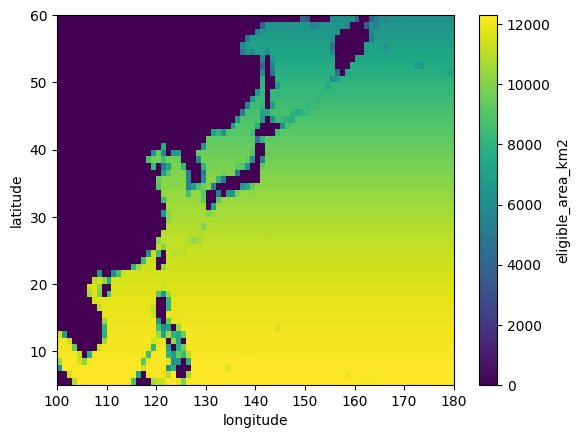

In [11]:
coarse_exposure.eligible_area_km2.plot()

## 3. Inspect the existing mask before modelling

Three fields are useful:

- `ocean_valid`: exactly what `_genesis_ocean_mask_1deg()` currently allows;
- `raw_ocean_fraction`: fractional ocean coverage from the underlying 0.1° mask;
- `eligible_fraction`: `raw_ocean_fraction` where the existing 1° rule allows genesis, otherwise 0.

This intentionally does **not** introduce a new coastline or a new basin polygon.

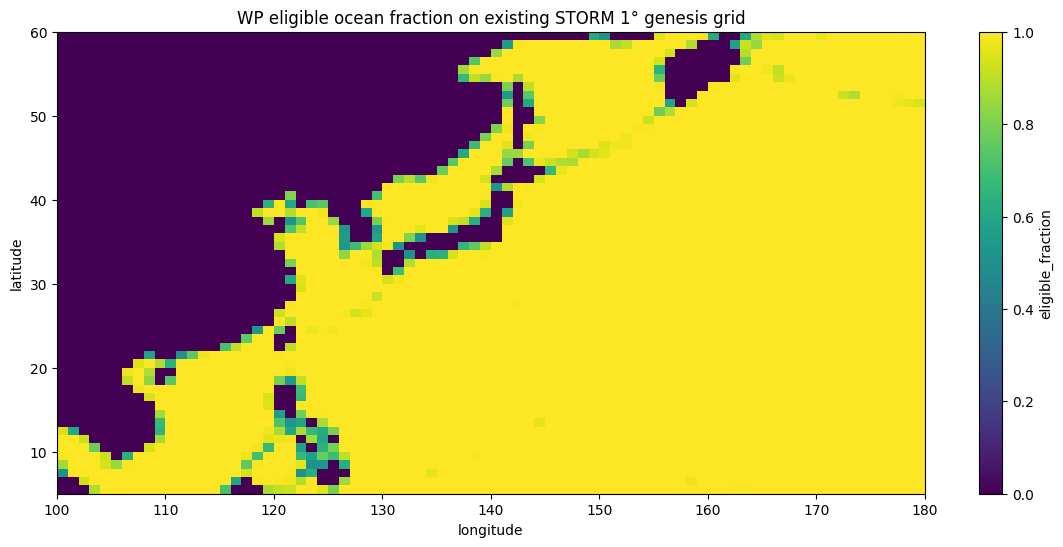

Eligible 1° cells: 3055 / 4400


In [12]:
fig, ax = plt.subplots(figsize=(14, 6))
coarse_exposure["eligible_fraction"].plot(ax=ax)
ax.set_title(f"{CFG.basin} eligible ocean fraction on existing STORM 1° genesis grid")
plt.show()

print(
    "Eligible 1° cells:",
    int(coarse_exposure["ocean_valid"].sum()),
    "/",
    ROWS * COLS,
)


### Why retain ocean fraction if the existing helper is binary?

The existing helper is ideal for **admissibility** and consistency with the simulator.
For the Poisson model, however, the exposure offset represents available ocean area.

A coastal cell that is 55% ocean and passes the existing `< 50% land` rule should not
contribute the same physical exposure as a 100% ocean cell. Therefore:

`ocean_valid` decides whether the cell exists in the genesis domain, while
`eligible_area_km2` determines how much exposure it contributes.

In [14]:
# Sanity checks: rejected cells must have zero exposure; accepted cells must have >0.
assert bool(
    (
        coarse_exposure["eligible_area_km2"].where(~coarse_exposure["ocean_valid"], 0)
        == 0
    ).all()
)

accepted = coarse_exposure["ocean_valid"].values
assert np.all(coarse_exposure["eligible_area_km2"].values[accepted] > 0)

coarse_exposure[
    ["ocean_valid", "raw_ocean_fraction", "eligible_fraction", "eligible_area_km2"]
]


<xarray.Dataset> Size: 111kB
Dimensions:             (latitude: 55, longitude: 80)
Coordinates:
  * latitude            (latitude) float64 440B 59.5 58.5 57.5 ... 7.5 6.5 5.5
  * longitude           (longitude) float64 640B 100.5 101.5 ... 178.5 179.5
Data variables:
    ocean_valid         (latitude, longitude) bool 4kB False False ... True True
    raw_ocean_fraction  (latitude, longitude) float64 35kB 0.0 0.0 ... 1.0 1.0
    eligible_fraction   (latitude, longitude) float64 35kB 0.0 0.0 ... 1.0 1.0
    eligible_area_km2   (latitude, longitude) float64 35kB 0.0 0.0 ... 1.231e+04

### Important consistency point

Do **not** add another `MIN_ELIGIBLE_FRACTION` threshold in the notebook.
`_genesis_ocean_mask_1deg()` already defines the existing STORM threshold:

```python
landfrac < 0.5
```

Adding a second threshold would silently create a different genesis domain.

In [15]:
# The existing helper is the only 1° admissibility threshold.
# No additional coastal-cell cutoff is applied here.
assert coarse_exposure["ocean_valid"].dtype == bool


## 4. Put environmental fields on the exact existing STORM 1° grid

Keep the project's 0–360° longitude convention.

The target coordinates come directly from `gm.basin_cell_centers()`, so the
environmental arrays, observed genesis counts, existing masks, and simulated
genesis probabilities all use the same row/column convention.

In [11]:
# FEATURES = ["pi", "rh600", "vws", "abs_vort850"]


def normalize_lon_360(ds: xr.Dataset, lon_name: str = "longitude") -> xr.Dataset:
    lon_new = ds[lon_name] % 360
    return ds.assign_coords({lon_name: lon_new}).sortby(lon_name)


def standardize_month_time(ds: xr.Dataset) -> xr.Dataset:
    t = pd.DatetimeIndex(ds.valid_time.values).to_period("M").to_timestamp()
    return ds.assign_coords(valid_time=t)

from time import time
def to_existing_storm_grid(ds: xr.Dataset, cfg: GenesisConfig) -> xr.Dataset:
    a = time()
    ds = normalize_lon_360(ds)
    print(time() - a)
    ds = standardize_month_time(ds)
    print(time() - a)
    ds = ds.sel(valid_time=ds.valid_time.dt.month.isin(ACTIVE_MONTHS[cfg.basin]))

    # xarray interpolation is safest with monotonic source coordinates.
    ds = ds.sortby("latitude").sortby("longitude")
    print(time() - a ) 
    # Target latitude is intentionally north->south to match genesis_matrix.py.
    out = ds.interp(latitude=LAT, longitude=LON)
    print(time() - a)
    return out


# Example if the fields are already suitable for direct interpolation:
env_1deg = to_existing_storm_grid(env_native, CFG)[
    list(NAME_MODEL.values())
]#[VARS_NAME]
#
# If your 0.25° preprocessing already has a preferred area/ocean-weighted
# 0.25° -> 1° aggregation, use that instead, but end on exactly LAT/LON above.


102.04689359664917
102.0517029762268
181.31805992126465
242.1454141139984


In [12]:
del(env_native)

### Recommended 0.25° → 1° aggregation

If your ERA5 fields are on a 0.25° grid aligned with the 1° cells, prefer an ocean-weighted block mean rather than interpolation. The exact implementation should reuse the land/basin mask already produced in your preprocessing pipeline.

Conceptually, for variable \(X\):

\[
X_{1^\circ}
=

rac{\sum_{j\in cell} X_j\,A_j\,I_{ocean,j}}
{\sum_{j\in cell} A_j\,I_{ocean,j}}.
\]

Do this consistently for ERA5 and any forecast fields that need regridding.

## 5. Historical genesis events

`genesis` should already contain exactly one row per storm under the definition you want the synthetic model to reproduce.

Recommended for compatibility with a STORM-like simulator:

- keep tropical/subtropical nature according to a fixed documented rule;
- identify the first fix at which the storm reaches the simulator's minimum wind threshold;
- use a single wind convention consistently;
- assign that time/location as the genesis event.

Do **not** fit a model to disturbance genesis if your simulator starts at tropical-storm genesis.

In [13]:
def normalize_lon_values(lon_values):
    """Use the same 0..360 convention as the STORM basin definitions."""
    return np.asarray(lon_values, dtype=float) % 360


def prepare_genesis_events(genesis: pd.DataFrame, cfg: GenesisConfig) -> pd.DataFrame:
    lat0, lat1, lon0, lon1 = gm.BOUNDARIES_BASINS(cfg.basin)

    g = genesis.copy()
    g["time"] = pd.to_datetime(g["time"])
    g["time_month"] = g["time"].dt.to_period("M").dt.to_timestamp()
    g["year"] = g["time"].dt.year
    g["month"] = g["time"].dt.month
    g["longitude"] = normalize_lon_values(g["longitude"])

    g = g[
        g["month"].isin(ACTIVE_MONTHS[cfg.basin])
        & g["latitude"].ge(lat0)
        & g["latitude"].lt(lat1)
        & g["longitude"].ge(lon0)
        & g["longitude"].lt(lon1)
    ].copy()

    return g


genesis = prepare_genesis_events(genesis_wp, CFG)

## 6. Assign observed genesis events to the existing 1° STORM cells

Rows are north-to-south and columns west-to-east, exactly as in
`basin_cell_centers()` and `_genesis_ocean_mask_1deg()`.

In [14]:
def assign_cells(df: pd.DataFrame, basin: str) -> pd.DataFrame:
    lat0, lat1, lon0, lon1 = gm.BOUNDARIES_BASINS(basin)
    rows = int(abs(lat1 - lat0))
    cols = int(abs(lon1 - lon0))

    out = df.copy()

    # Row 0 is [lat1-1, lat1), centered at lat1-0.5.
    ilat = np.floor(lat1 - out["latitude"].to_numpy()).astype(int)
    ilon = np.floor(out["longitude"].to_numpy() - lon0).astype(int)

    valid = (ilat >= 0) & (ilat < rows) & (ilon >= 0) & (ilon < cols)

    out = out.loc[valid].copy()
    out["ilat"] = ilat[valid]
    out["ilon"] = ilon[valid]
    out["cell_lat"] = LAT[out["ilat"].to_numpy()]
    out["cell_lon"] = LON[out["ilon"].to_numpy()]

    return out


genesis = assign_cells(genesis, CFG.basin)


### Bucket regions

In [15]:
def assign_genesis_region(lat, lon):
    """
    lon in 0..360 convention.
    """

    # SCS
    if 0 <= lat < 30 and 100 <= lon < 120:
        return "scs"

    # NWP Nortwhest
    if 17 <= lat < 40 and 120 <= lon < 140:
        return "nwp_nw"

    # NWP Southwest
    if 0 <= lat < 17 and 120 <= lon < 140:
        return "nwp_sw"

    # NWP Northeast
    if 17 <= lat < 40 and 140 <= lon < 180:
        return "nwp_se"

    # Everything farther north in the Pacific
    return "nwp_ne"


genesis["region"] = [
    assign_genesis_region(lat, lon)
    for lat, lon in zip(
        genesis["latitude"],
        genesis["longitude"],
    )
]

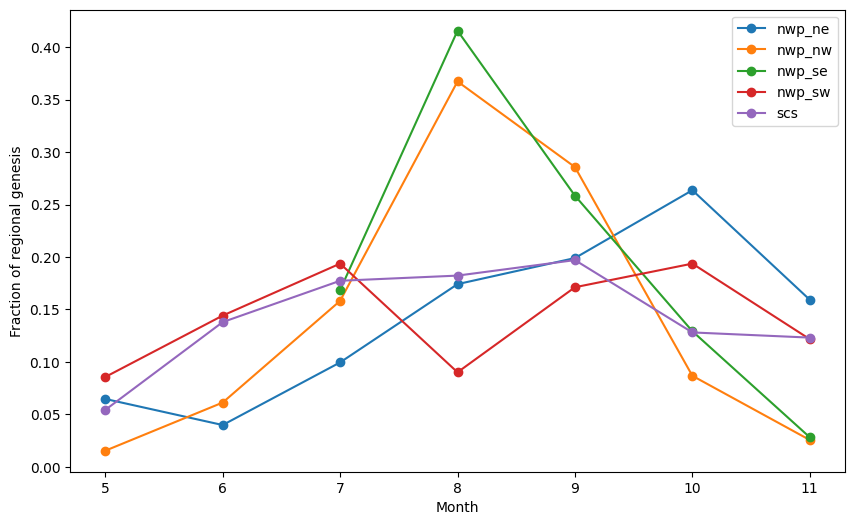

In [16]:
regional_month = (
    genesis.groupby(["region", "month"]).size().rename("count").reset_index()
)

regional_month["fraction"] = regional_month["count"] / regional_month.groupby("region")[
    "count"
].transform("sum")

fig, ax = plt.subplots(figsize=(10, 6))

for region, d in regional_month.groupby("region"):
    ax.plot(
        d["month"],
        d["fraction"],
        marker="o",
        label=region,
    )

ax.set_xlabel("Month")
ax.set_ylabel("Fraction of regional genesis")
ax.legend()

plt.show()

## 7. Build the cell-month modelling table

Every eligible 1° cell and every historical active-season month is one row.

The response is:

`genesis_count`

Most rows will be zero. That is expected and is **not** by itself evidence of zero inflation.

Exposure is:

\[
E_{iym}
=

rac{A^{eligible}_i}{100000\ km^2}
	imes

rac{days(m)}{30.44}.
\]

The scale constants only make the intercept readable.

In [17]:
def build_model_table(
    env_1deg: xr.Dataset,
    coarse_exposure: xr.Dataset,
    genesis_cells: pd.DataFrame,
    cfg: GenesisConfig,
) -> pd.DataFrame:
    missing = [v for v in list(NAME_MODEL.values()) if v not in env_1deg]
    if missing:
        raise KeyError(f"Missing environmental variables: {missing}")

    env_df = env_1deg[list(NAME_MODEL.values())].to_dataframe().reset_index()
    env_df["time"] = pd.to_datetime(env_df["valid_time"])
    env_df["year"] = env_df["time"].dt.year
    env_df["month"] = env_df["time"].dt.month

    exposure_df = (
        coarse_exposure[["ocean_valid", "eligible_area_km2", "eligible_fraction"]]
        .to_dataframe()
        .reset_index()
    )


    df = env_df.merge(exposure_df, on=["latitude", "longitude"], how="left")

    counts = (
        genesis_cells.groupby(["time_month", "cell_lat", "cell_lon"])
        .size()
        .rename("genesis_count")
        .reset_index()
        .rename(
            columns={
                "time_month": "time",
                "cell_lat": "latitude",
                "cell_lon": "longitude",
            }
        )
    )

    df = df.merge(counts, on=["time", "latitude", "longitude"], how="left")
    df["genesis_count"] = df["genesis_count"].fillna(0).astype(int)

    days = df["time"].dt.days_in_month.astype(float)
    df["exposure"] = (df["eligible_area_km2"] / cfg.area_unit_km2) * (
        days / cfg.reference_month_days
    )

    valid = (
        df["ocean_valid"].fillna(False)
        & (df["exposure"] > 0)
        & np.isfinite(df[list(NAME_MODEL.values())]).all(axis=1)
    )

    df = df.loc[valid].copy()
    df["log_exposure"] = np.log(df["exposure"])

    return df


model_df = build_model_table(env_1deg, coarse_exposure, genesis, CFG)
model_df.head()


,valid_time,latitude,longitude,pi,vws,rh600,eta850,w500,isobaricInhPa,time,year,month,ocean_valid,eligible_area_km2,eligible_fraction,genesis_count,exposure,log_exposure
49,1980-05-01,59.5,149.5,0.000000e+00,7.363624,67.584137,0.00005,0.002621,500.0,1980-05-01,1980,5,True,3827.933129,0.61,0,0.038988,-3.244513
50,1980-05-01,59.5,150.5,0.000000e+00,7.564113,67.824371,0.00005,0.019222,500.0,1980-05-01,1980,5,True,3200.403108,0.51,0,0.032596,-3.423561
55,1980-05-01,59.5,155.5,0.000000e+00,7.563228,67.990387,0.00005,-0.036442,500.0,1980-05-01,1980,5,True,5961.535201,0.95,0,0.060718,-2.801510
66,1980-05-01,59.5,166.5,0.000000e+00,7.487061,61.412258,0.00005,0.008480,500.0,1980-05-01,1980,5,True,5898.782199,0.94,0,0.060079,-2.812092
67,1980-05-01,59.5,167.5,8.604574e-09,7.629346,61.261868,0.00005,0.003353,500.0,1980-05-01,1980,5,True,6275.300212,1.00,0,0.063914,-2.750217


## 8. Basic data diagnostics

Before fitting:

- verify observed annual/monthly counts;
- inspect environmental ranges at genesis vs all eligible ocean cells;
- inspect predictor correlation;
- check that no one variable contains unit mistakes.

In [18]:
def summarize_training_data(df: pd.DataFrame):
    print(f"Rows: {len(df):,}")
    print(f"Observed genesis events: {df.genesis_count.sum():,}")
    print()
    print("Events by month:")
    print(df.groupby("month")["genesis_count"].sum())
    print()
    print("Feature summary:")
    print(df[list(NAME_MODEL.values())].describe().T)
    print()
    print("Feature correlation:")
    print(df[list(NAME_MODEL.values())].corr())

summarize_training_data(model_df)

Rows: 962,278
Observed genesis events: 994

Events by month:
month
5      46
6      77
7     160
8     238
9     218
10    161
11     94
Name: genesis_count, dtype: int64

Feature summary:
           count       mean        std       min        25%        50%  \
pi      962278.0  41.981544  27.022844  0.000000  11.547830  57.136103   
vws     962278.0  15.708849  10.854310  0.010433   7.660624  12.639009   
rh600   962278.0  51.062356  14.177978  6.100260  41.258495  50.564825   
eta850  962278.0   0.000043   0.000011  0.000000   0.000039   0.000050   
w500    962278.0  -0.017727   0.041060 -0.638500  -0.041561  -0.012034   

              75%        max  
pi      65.314363  76.883759  
vws     21.269816  66.845291  
rh600   61.151484  88.632706  
eta850   0.000050   0.000050  
w500     0.011117   0.365839  

Feature correlation:
              pi       vws     rh600    eta850      w500
pi      1.000000 -0.412575  0.152893 -0.544972 -0.190470
vws    -0.412575  1.000000 -0.332039  0.2294

## 9. Temporal split: never split random grid rows

A random train/test split would leak the same years and monthly environments into both samples.

The first validation should hold out entire years.

In [19]:
def split_by_year(df: pd.DataFrame, first_test_year: int):
    train = df[df["year"] < first_test_year].copy()
    test = df[df["year"] >= first_test_year].copy()
    return train, test

train, test = split_by_year(model_df, CFG.first_test_year)

## 10. Standardize environmental predictors using training data only

This is mainly numerical conditioning and makes coefficient magnitudes easier to compare.

In [20]:
def fit_standardizer(train: pd.DataFrame, features: list[str]):
    params = {}
    for col in features:
        mu = train[col].mean()
        sd = train[col].std()
        if not np.isfinite(sd) or sd == 0:
            raise ValueError(f"Invalid standard deviation for {col}: {sd}")
        params[col] = (mu, sd)
    return params

def apply_standardizer(df: pd.DataFrame, params):
    out = df.copy()
    for col, (mu, sd) in params.items():
        out[f"z_{col}"] = (out[col] - mu) / sd
    return out

scaler = fit_standardizer(train, list(NAME_MODEL.values()))
train = apply_standardizer(train, scaler)
test = apply_standardizer(test, scaler)

## 11. Fit two models

### Baseline M0
Seasonality only.

### Environmental M1
Seasonality + PI + RH + VWS + absolute vorticity.

For V1, month is categorical. This is transparent and handles unusual basin seasonal cycles without forcing a sinusoidal shape.

Later we can replace selected linear terms by physically motivated saturating functions or GAM splines.

In [26]:
list(NAME_MODEL.values())

['pi', 'vws', 'rh600', 'eta850', 'w500']

In [21]:
def fit_poisson_models(train: pd.DataFrame):
    baseline_formula = "genesis_count ~ C(month)"

    env_formula2 = (
        "genesis_count ~ C(month)"
        " + z_pi"
        " + z_vws"
        " + z_rh600"
        " + z_eta850"
        " + z_w500"
    )

    env_formula = (
            "genesis_count ~ C(month)"
            " + z_pi"
            " + z_vws"
            " + z_rh600"
            " + z_eta850"
        )

    m0 = smf.glm(
        baseline_formula,
        data=train,
        family=sm.families.Poisson(),
        offset=train["log_exposure"],
    ).fit()

    m1 = smf.glm(
        env_formula,
        data=train,
        family=sm.families.Poisson(),
        offset=train["log_exposure"],
    ).fit()

    m2 = smf.glm(
            env_formula2,
            data=train,
            family=sm.families.Poisson(),
            offset=train["log_exposure"],
        ).fit()



    return m0, m1, m2

m0, m1, m2 = fit_poisson_models(train)
print(m1.summary())
print(m2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:          genesis_count   No. Observations:               769813
Model:                            GLM   Df Residuals:                   769802
Model Family:                 Poisson   Df Model:                           10
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -5138.4
Date:                Fri, 09 Oct 2026   Deviance:                       8694.4
Time:                        18:29:41   Pearson chi2:                 3.93e+05
No. Iterations:                    10   Pseudo R-squ. (CS):           0.002641
Covariance Type:            nonrobust                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         -6.7323      0.184    -36.

## 12. First model sanity checks

The expected physical signs are useful diagnostics, not hard constraints:

- PI: generally positive;
- RH: generally positive;
- VWS: generally negative;
- absolute vorticity: generally positive, potentially saturating.

A wrong sign does not automatically imply a bug because predictors are correlated. It should trigger:

- unit checks;
- correlation checks;
- univariate response plots;
- blocked-validation comparisons.

Also inspect Poisson dispersion, but judge overdispersion primarily at the **basin-month/year** level rather than from the enormous number of tiny cell means.

In [22]:
def pearson_dispersion(result) -> float:
    return float(np.sum(result.resid_pearson**2) / result.df_resid)

print("M0 dispersion:", pearson_dispersion(m0))
print("M1 dispersion:", pearson_dispersion(m1))
print("M2 dispersion:", pearson_dispersion(m2))

M0 dispersion: 0.8855403659075385
M1 dispersion: 0.5108686903388133
M2 dispersion: 0.47750294718570724


## 13. Held-out predictions

`statsmodels` returns the expected number of genesis events in each cell-month because the exposure offset is supplied at prediction time.

Therefore:

\[
\hat\Lambda_{ym} = \sum_i \hat\mu_{iym}
\]

is automatically the predicted basin-month frequency.

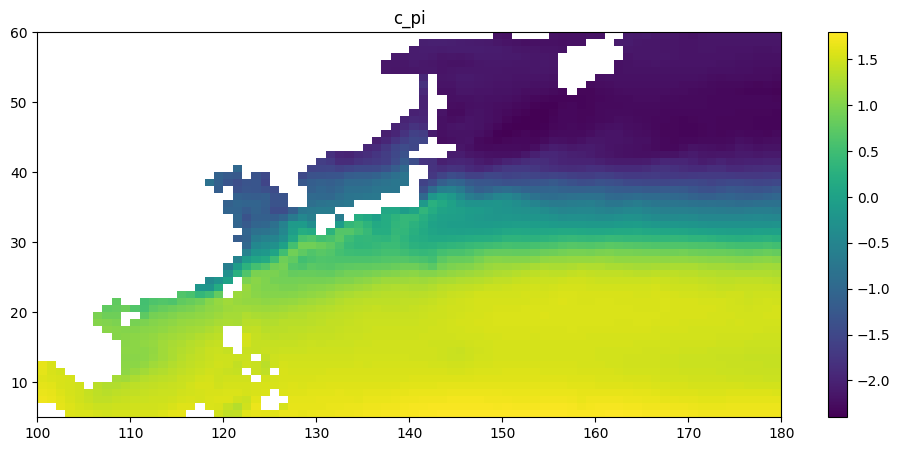

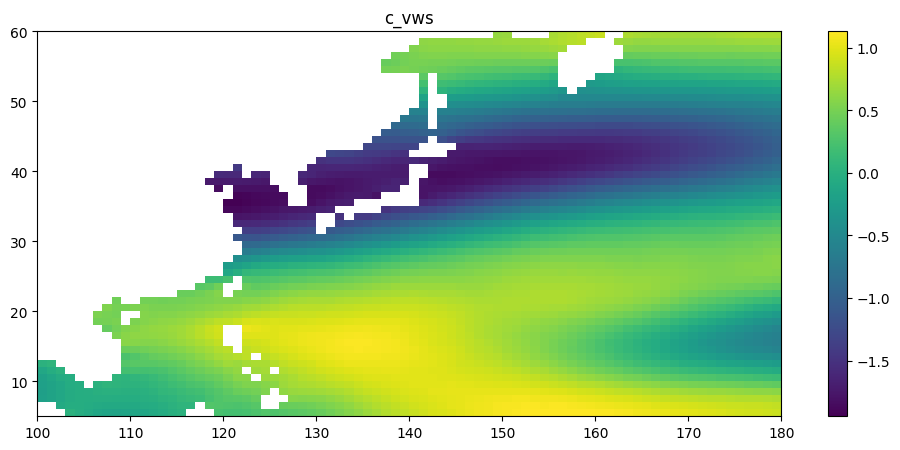

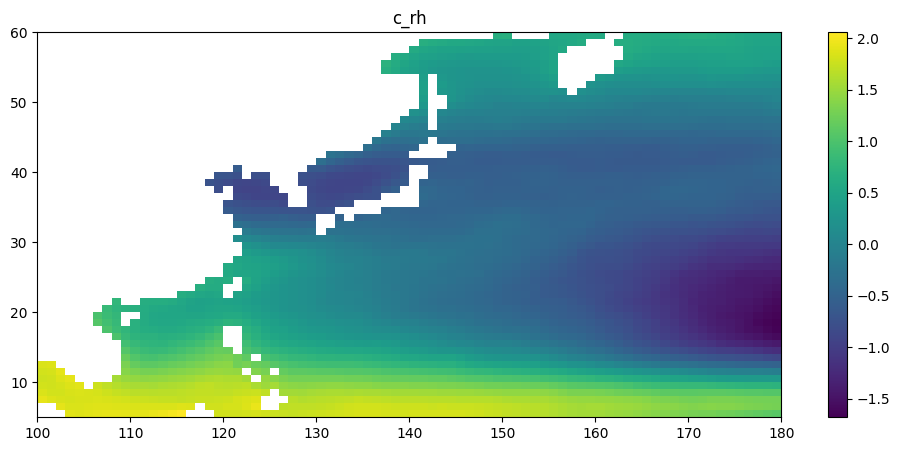

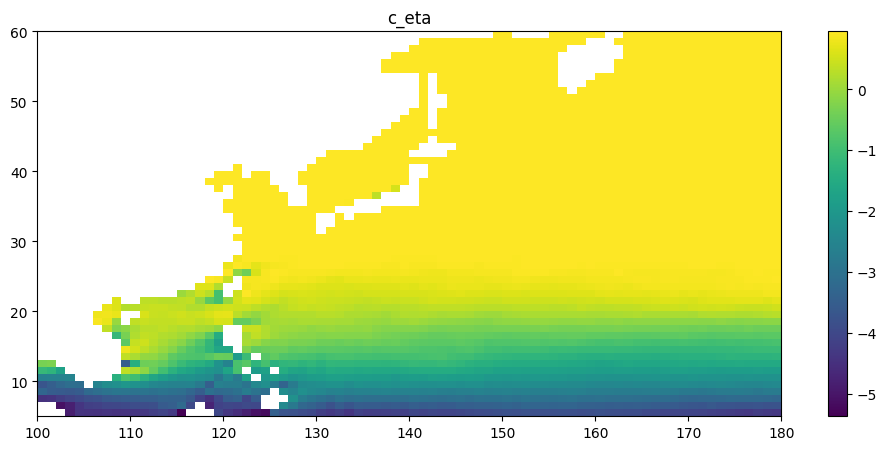

In [23]:
def add_predictions(df: pd.DataFrame, model, name: str) -> pd.DataFrame:
    out = df.copy()
    out[name] = model.predict(
        out,
        offset=out["log_exposure"],
    )
    return out

test = add_predictions(test, m0, "mu_m0")
test = add_predictions(test, m1, "mu_m1")
test = add_predictions(test, m2, "mu_m2")

params = m1.params

for var in ["z_pi", "z_vws", "z_rh600", "z_eta850"]:
    test[f"contrib_{var}"] = params[var] * test[var]

diagnostic = (
    test.groupby(["latitude", "longitude"])
    .agg(
        expected=("mu_m1", "sum"),
        observed=("genesis_count", "sum"),
        z_pi=("z_pi", "mean"),
        z_vws=("z_vws", "mean"),
        z_rh600=("z_rh600", "mean"),
        z_eta850=("z_eta850", "mean"),
        c_pi=("contrib_z_pi", "mean"),
        c_vws=("contrib_z_vws", "mean"),
        c_rh=("contrib_z_rh600", "mean"),
        c_eta=("contrib_z_eta850", "mean"),
    )
    .reset_index()
)

diagnostic.sort_values("expected", ascending=False).head(30)

for col in ["c_pi", "c_vws", "c_rh", "c_eta"]:
    a = diagnostic.pivot(
        index="latitude",
        columns="longitude",
        values=col,
    )

    fig, ax = plt.subplots(figsize=(12, 5))
    im = ax.pcolormesh(
        a.columns,
        a.index,
        a.values,
        shading="auto",
    )
    ax.set_title(col)
    plt.colorbar(im, ax=ax)
    plt.show()

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2


def binned_genesis_rate(
    df,
    variable,
    n_bins=20,
    q=(0.01, 0.99),
):
    d = (
        df[
            [
                variable,
                "genesis_count",
                "exposure",
            ]
        ]
        .dropna()
        .copy()
    )

    # Remove only the most extreme tails for visualization.
    # Do not do this automatically in the fitted model.
    lo, hi = d[variable].quantile(q)
    d = d[d[variable].between(lo, hi)]

    d["bin"] = pd.qcut(
        d[variable],
        q=n_bins,
        duplicates="drop",
    )

    out = (
        d.groupby("bin", observed=True)
        .agg(
            x=(variable, "mean"),
            count=("genesis_count", "sum"),
            exposure=("exposure", "sum"),
            n=("genesis_count", "size"),
        )
        .reset_index(drop=True)
    )

    out["rate"] = out["count"] / out["exposure"]

    # Exact Poisson confidence interval for number of events
    alpha = 0.05

    out["rate_low"] = np.where(
        out["count"] > 0,
        0.5 * chi2.ppf(alpha / 2, 2 * out["count"]) / out["exposure"],
        0.0,
    )

    out["rate_high"] = (
        0.5
        * chi2.ppf(
            1 - alpha / 2,
            2 * (out["count"] + 1),
        )
        / out["exposure"]
    )

    return out

variables = [
    "pi",
    "rh600",
    "vws",
    "eta_clip",
    "w500"
]

for variable in variables:
    d = binned_genesis_rate(
        train_eta,
        variable,
        n_bins=20,
    )

    d_bis = binned_genesis_rate(
            test_eta,
            variable,
            n_bins=20,
        )

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.plot(
        d["x"],
        np.log(d["rate"]),
        marker="o",
    )

    ax.plot(
            d_bis["x"],
            np.log(d_bis["rate"]),
            marker="x",
        )

    ax.fill_between(
        d["x"],
        np.log(d["rate_low"].replace(0, np.nan)),
        np.log(d["rate_high"]),
        alpha=0.2,
    )

    ax.set_xlabel(variable)
    ax.set_ylabel("log(genesis rate)")
    ax.set_title(f"Empirical genesis response to {variable}")

    plt.show()

NameError: name 'train_eta' is not defined

### Basin-month verification

The sum of independent Poisson variables is Poisson, so the aggregate predicted basin-month count is:

\[
N_{ym}\sim Pois(\Lambda_{ym}),
\qquad
\Lambda_{ym}=\sum_i\mu_{iym}.
\]

This gives a natural probabilistic score without any extra calibration layer.

In [24]:
def basin_month_scores(df: pd.DataFrame, mu_col: str) -> tuple[pd.DataFrame, dict]:
    agg = (
        df.groupby(["year", "month"], as_index=False)
        .agg(
            observed=("genesis_count", "sum"),
            lambda_pred=(mu_col, "sum"),
        )
    )

    agg["log_score"] = poisson.logpmf(
        agg["observed"],
        np.clip(agg["lambda_pred"], 1e-12, None),
    )

    metrics = {
        "mean_log_score": agg["log_score"].mean(),
        "bias": (agg["lambda_pred"] - agg["observed"]).mean(),
        "mae": np.abs(agg["lambda_pred"] - agg["observed"]).mean(),
        "rmse": np.sqrt(
            np.mean((agg["lambda_pred"] - agg["observed"]) ** 2)
        ),
    }
    return agg, metrics

agg0, score0 = basin_month_scores(test, "mu_m0")
agg1, score1 = basin_month_scores(test, "mu_m1")
agg2, score2 = basin_month_scores(test, "mu_m2")
print("M0:", score0)
print("M1:", score1)
print("M2: ", score2)

M0: {'mean_log_score': np.float64(-1.8217807162074329), 'bias': np.float64(-0.02376968186001889), 'mae': np.float64(1.2919181134034283), 'rmse': np.float64(1.6146793336538938)}
M1: {'mean_log_score': np.float64(-1.8195725822694664), 'bias': np.float64(0.21538977723155886), 'mae': np.float64(1.2596722044178033), 'rmse': np.float64(1.5809367851291443)}
M2:  {'mean_log_score': np.float64(-1.7854305686224083), 'bias': np.float64(0.18489935134224864), 'mae': np.float64(1.179070848689323), 'rmse': np.float64(1.4809509504961118)}


### Spatial held-out log score

For the gridded point-process approximation, the cell-month Poisson log likelihood is also the natural spatial occurrence score.

Compare models only on exactly the same held-out rows.

In [25]:
def heldout_cell_loglik(df: pd.DataFrame, mu_col: str) -> float:
    y = df["genesis_count"].to_numpy()
    mu = np.clip(df[mu_col].to_numpy(), 1e-15, None)
    return float(poisson.logpmf(y, mu).sum())

print("M0 cell loglik:", heldout_cell_loglik(test, "mu_m0"))
print("M1 cell loglik:", heldout_cell_loglik(test, "mu_m1"))
print("M2 cell loglik:", heldout_cell_loglik(test, "mu_m2"))

M0 cell loglik: -1519.7489121130384
M1 cell loglik: -1267.4582549164636
M2 cell loglik: -1259.1734349655737


### Threshold eta

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import poisson
from patsy import bs


In [23]:
def predict_mu(model, df):
    return model.predict(
        df,
        offset=df["log_exposure"],
    )


def cell_log_score(df, mu):
    """
    Total held-out Poisson log-likelihood at cell-month level.
    Higher = better.
    """
    y = df["genesis_count"].to_numpy()
    mu = np.clip(np.asarray(mu), 1e-15, None)

    return poisson.logpmf(y, mu).sum()


def basin_month_score(df, mu):
    """
    Aggregate cell expectations to basin-month before scoring.
    This evaluates the frequency component more directly.
    """
    d = df[["year", "month", "genesis_count"]].copy()

    d["mu"] = mu

    agg = d.groupby(["year", "month"], as_index=False).agg(
        observed=("genesis_count", "sum"),
        expected=("mu", "sum"),
    )

    agg["log_score"] = poisson.logpmf(
        agg["observed"],
        np.clip(agg["expected"], 1e-15, None),
    )

    return {
        "monthly_log_score": agg["log_score"].sum(),
        "monthly_mean_log_score": agg["log_score"].mean(),
        "monthly_bias": (agg["expected"] - agg["observed"]).mean(),
        "monthly_rmse": np.sqrt(np.mean((agg["expected"] - agg["observed"]) ** 2)),
    }


def evaluate_model(name, model, test_df):
    mu = predict_mu(model, test_df)

    scores = basin_month_score(test_df, mu)

    return {
        "model": name,
        "cell_log_score": cell_log_score(
            test_df,
            mu,
        ),
        **scores,
    }


In [24]:
FORMULA_LINEAR = "genesis_count ~ C(month) + z_pi + z_rh600 + z_vws + z_eta850"

m_linear = smf.glm(
    formula=FORMULA_LINEAR,
    data=train,
    family=sm.families.Poisson(),
    offset=train["log_exposure"],
).fit()


In [25]:
results = [
    evaluate_model(
        "linear",
        m_linear,
        test,
    )
]

pd.DataFrame(results)


,model,cell_log_score,monthly_log_score,monthly_mean_log_score,monthly_bias,monthly_rmse
0,linear,-1267.458255,-114.633073,-1.819573,0.21539,1.580937


In [26]:
ETA_THRESHOLDS = np.arange(
    2.5e-5,
    5.01e-5,
    0.25e-5,
)

def prepare_clipped_eta(
    train,
    test,
    threshold,
):
    train_tmp = train.copy()
    test_tmp = test.copy()

    train_tmp["eta_clip"] = np.minimum(
        train_tmp["eta850"],
        threshold,
    )

    test_tmp["eta_clip"] = np.minimum(
        test_tmp["eta850"],
        threshold,
    )

    # Standardization fitted ONLY on training period
    mean_eta = train_tmp["eta_clip"].mean()
    std_eta = train_tmp["eta_clip"].std()

    train_tmp["z_eta_clip"] = (train_tmp["eta_clip"] - mean_eta) / std_eta

    test_tmp["z_eta_clip"] = (test_tmp["eta_clip"] - mean_eta) / std_eta

    return train_tmp, test_tmp

In [27]:
eta_results = []
eta_models = {}

for threshold in ETA_THRESHOLDS:
    train_eta, test_eta = prepare_clipped_eta(
        train,
        test,
        threshold,
    )

    formula = "genesis_count ~ C(month) + z_pi + z_rh600 + z_vws + z_eta_clip + z_w500"

    model = smf.glm(
        formula=formula,
        data=train_eta,
        family=sm.families.Poisson(),
        offset=train_eta["log_exposure"],
    ).fit()

    score = evaluate_model(
        f"eta_clip_{threshold:.2e}",
        model,
        test_eta,
    )

    score["eta_threshold"] = threshold

    eta_results.append(score)
    eta_models[threshold] = (
        model,
        train_eta,
        test_eta,
    )


KeyboardInterrupt: 

In [32]:
eta_scores = pd.DataFrame(eta_results)

eta_scores[
    [
        "eta_threshold",
        "cell_log_score",
        "monthly_log_score",
        "monthly_rmse",
    ]
].sort_values(
    "cell_log_score",
    ascending=False,
)


,eta_threshold,cell_log_score,monthly_log_score,monthly_rmse
9,0.000048,-1258.204403,-112.257108,1.464853
8,0.000045,-1259.063517,-111.962990,1.446953
10,0.000050,-1259.173435,-112.482126,1.480951
7,0.000043,-1261.229980,-111.632667,1.433202
6,0.000040,-1265.665182,-111.292567,1.426654
5,0.000038,-1272.432279,-111.017273,1.424102
4,0.000035,-1282.263543,-110.994672,1.426268
3,0.000033,-1294.471098,-111.044991,1.426989
2,0.000030,-1305.845274,-111.079121,1.424807
1,0.000028,-1316.800813,-111.105293,1.431854


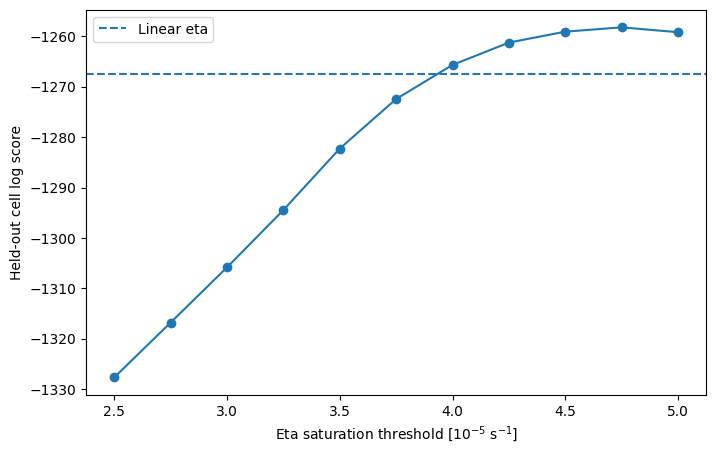

In [33]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    eta_scores["eta_threshold"] * 1e5,
    eta_scores["cell_log_score"],
    marker="o",
)

ax.axhline(
    results[0]["cell_log_score"],
    linestyle="--",
    label="Linear eta",
)

ax.set_xlabel(r"Eta saturation threshold [$10^{-5}$ s$^{-1}$]")
ax.set_ylabel("Held-out cell log score")
ax.legend()

plt.show()


### Spatial Approach with PATSY CR/TE

In [28]:
train_eta, test_eta = prepare_clipped_eta(
        train,
        test,
        4.5e-5,
    )

FORMULA_BASE = "genesis_count ~ C(month) + z_pi + z_rh600 + z_vws + z_eta_clip + z_w500"

m_base = smf.glm(
    FORMULA_BASE,
    data=train_eta,
    family=sm.families.Poisson(),
    offset=train_eta["log_exposure"],
).fit()


FORMULA_REGION_MONTH = (
    "genesis_count ~ C(region) * C(month)"
    " + z_pi"
    " + z_rh600"
    " + z_vws"
    " + z_eta_clip"
    " + z_w500"
)


train_eta["region"] = [
    assign_genesis_region(lat, lon)
    for lat, lon in zip(
        train_eta["latitude"],
        train_eta["longitude"],
    )
]

test_eta["region"] = [
    assign_genesis_region(lat, lon)
    for lat, lon in zip(
        test_eta["latitude"],
        test_eta["longitude"],
    )
]

m_region_month = smf.glm(
    FORMULA_REGION_MONTH,
    data=train_eta,
    family=sm.families.Poisson(),
    offset=train_eta["log_exposure"],
).fit()





In [29]:
region_grid = (
    train_eta[["latitude", "longitude", "region"]]
    .drop_duplicates(["latitude", "longitude"])
    .pivot(
        index="latitude",
        columns="longitude",
        values="region",
    )
)

import numpy as np
from scipy.ndimage import gaussian_filter

regions = sorted(train_eta["region"].unique())

hard_masks = {}

for region in regions:
    hard_masks[region] = (region_grid.values == region).astype(float)


SIGMA_REGION = 3.0

SIGMA_CV = [3]

sigma_soft_masks = {}
sigma_weight_df = {}
m_sigma_cv = {}
sigma_results = []
for sigma in SIGMA_CV:
    soft_masks = {}

    for region in regions:
        soft_masks[region] = gaussian_filter(
            hard_masks[region],
            sigma=sigma,
            mode="nearest",
        )

    total = np.zeros_like(next(iter(soft_masks.values())))

    for field in soft_masks.values():
        total += field

    total = np.where(
        total > 0,
        total,
        np.nan,
    )

    for region in regions:
        soft_masks[region] = soft_masks[region] / total


    weights_df = []

    lat_values = region_grid.index.to_numpy()
    lon_values = region_grid.columns.to_numpy()

    for i, lat in enumerate(lat_values):
        for j, lon in enumerate(lon_values):
            row = {
                "latitude": lat,
                "longitude": lon,
            }

            for region in regions:
                row[f"w_{region}"] = soft_masks[region][i, j]

            weights_df.append(row)

    weights_df = pd.DataFrame(weights_df)

    train_soft = train_eta.merge(
            weights_df,
            on=["latitude", "longitude"],
            how="left",
        )

    test_soft = test_eta.merge(
        weights_df,
        on=["latitude", "longitude"],
        how="left",
    )
    REFERENCE_REGION = "subtropical"

    varying_regions = [r for r in regions if r != REFERENCE_REGION]
    region_terms = " + ".join(f"w_{r}" for r in varying_regions)

    interaction_terms = " + ".join(f"w_{r}:C(month)" for r in varying_regions)

    FORMULA_SOFT_REGION_MONTH = (
        "genesis_count ~ C(month)"
        " + z_pi"
        " + z_rh600"
        " + z_vws"
        " + z_eta_clip"
        " + z_w500"
        f" + {region_terms}"
        #f" + {interaction_terms}"
    )
    m_soft_region_month = smf.glm(
        formula=FORMULA_SOFT_REGION_MONTH,
        data=train_soft,
        family=sm.families.Poisson(),
        offset=train_soft["log_exposure"],
    ).fit()


    score = evaluate_model(
        f"sigma_{sigma:02d}",
        m_soft_region_month,
        test_soft,
    )

    score["sigma"] = sigma

    sigma_results.append(score)
    m_sigma_cv[sigma] = (
        m_soft_region_month,
        train_soft,
        test_soft,
    )




In [36]:

sigma_scores = pd.DataFrame(sigma_results)

sigma_scores[
    [
        "sigma",
        "cell_log_score",
        "monthly_log_score",
        "monthly_rmse",
    ]
].sort_values(
    "cell_log_score",
    ascending=False,
)


,sigma,cell_log_score,monthly_log_score,monthly_rmse
0,3,-1245.074503,-110.981579,1.449927


In [ ]:


import numpy as np
from scipy.ndimage import gaussian_filter
soft_masks = {}
for region in regions:
    soft_masks[region] = gaussian_filter(
        hard_masks[region],
        sigma=3.0,
        mode="nearest",
    )

total = np.zeros_like(next(iter(soft_masks.values())))

for field in soft_masks.values():
    total += field

total = np.where(
    total > 0,
    total,
    np.nan,
)

for region in regions:
    soft_masks[region] = soft_masks[region] / total


weights_df = []

lat_values = region_grid.index.to_numpy()
lon_values = region_grid.columns.to_numpy()

for i, lat in enumerate(lat_values):
    for j, lon in enumerate(lon_values):
        row = {
            "latitude": lat,
            "longitude": lon,
        }

        for region in regions:
            row[f"w_{region}"] = soft_masks[region][i, j]

        weights_df.append(row)

weights_df = pd.DataFrame(weights_df)

train_soft = train_eta.merge(
        weights_df,
        on=["latitude", "longitude"],
        how="left",
    )

test_soft = test_eta.merge(
    weights_df,
    on=["latitude", "longitude"],
    how="left",
)


REFERENCE_REGION = "scs"

varying_regions = [r for r in regions if r != REFERENCE_REGION]
region_terms = " + ".join(f"w_{r}" for r in varying_regions)

interaction_terms = " + ".join(f"w_{r}:C(month)" for r in varying_regions)

FORMULA_SOFT_REGION_MONTH = (
    "genesis_count ~ C(month)"
    " + z_pi"
    " + z_rh600"
    " + z_vws"
    " + z_eta_clip"
    " + z_w500"
    f" + {region_terms}"
    #f" + {interaction_terms}"
)
m_soft_region_month = smf.glm(
    formula=FORMULA_SOFT_REGION_MONTH,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
).fit()


year_center = train_soft["year"].mean()

train_soft["year_scaled"] = (train_soft["year"] - year_center) / 10
train_soft["eio"] = train_soft["year"].map(wnp_predictors.set_index("year")["eio"])

train_soft["eio_raw"] = train_soft["year"].map(eio_raw)



train_soft["sstg"] = train_soft["year"].map(wnp_predictors.set_index("year")["sstg"])
train_soft["sstg_raw"] = train_soft["year"].map(sstg_raw)
test_soft["year_scaled"] = (test_soft["year"] - year_center) / 10
test_soft["eio"] = test_soft["year"].map(wnp_predictors.set_index("year")["eio"])

test_soft["sstg"] = test_soft["year"].map(wnp_predictors.set_index("year")["sstg"])
test_soft["eio_raw"] = test_soft["year"].map(eio_raw)
test_soft["sstg_raw"] = test_soft["year"].map(sstg_raw)

eio_mean, eio_std = train_soft["eio"].mean(), train_soft["eio"].std()
sstg_mean, sstg_std = train_soft["sstg"].mean(), train_soft["sstg"].std()
eio_raw_mean, eio_raw_std = train_soft["eio_raw"].mean(), train_soft["eio_raw"].std()
sstg_raw_mean, sstg_raw_std = train_soft["sstg_raw"].mean(), train_soft["sstg_raw"].std()



train_soft["eio"] = (train_soft["eio"] - eio_mean) / eio_std
train_soft["sstg"] = (train_soft["sstg"] - sstg_mean) / sstg_std
train_soft["sstg_raw"] = (
    train_soft["sstg_raw"] - sstg_raw_mean
) / sstg_raw_std
train_soft["eio_raw"] = (
    train_soft["eio_raw"] - eio_raw_mean
) / eio_raw_std
test_soft["eio"] = (test_soft["eio"] - eio_mean) / eio_std
test_soft["eio_raw"] = (test_soft["eio_raw"] - eio_raw_mean) / eio_raw_std
test_soft["sstg"] = (test_soft["sstg"] - sstg_mean) / sstg_std
test_soft["sstg_raw"] = (test_soft["sstg_raw"] - sstg_raw_mean) / sstg_raw_std


train_soft = train_soft.merge(
    eio_dynamic_df,
    on=["year", "month"],
    how="left",
)

test_soft = test_soft.merge(
    eio_dynamic_df,
    on=["year", "month"],
    how="left",
)


mu_eio = train_soft["eio_dynamic"].mean()
sd_eio = train_soft["eio_dynamic"].std()

train_soft["z_eio_dynamic"] = (train_soft["eio_dynamic"] - mu_eio) / sd_eio

test_soft["z_eio_dynamic"] = (test_soft["eio_dynamic"] - mu_eio) / sd_eio


FORMULA_TREND = (
    "genesis_count ~ C(month)"
    " + z_pi"
    " + z_rh600"
    " + z_vws"
    " + z_eta_clip"
    " + z_w500"
    f" + {region_terms}"
    # " + rsst"
)

m_trend = smf.glm(
    formula=FORMULA_TREND,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
).fit()


FORMULA_TREND_BIS = (
    "genesis_count ~ " # C(month)
    " + z_pi"
    " + z_rh600"
    " + z_vws"
    " + z_eta_clip"
    " + z_w500"
    f" + {region_terms}"
    # " + rsst"
)

m_trend_bis = smf.glm(
    formula=FORMULA_TREND_BIS,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
).fit()


FORMULA_TREND_TER = (
    "genesis_count ~ "  # C(month)"
    " + z_pi"
    " + z_rh600"
    " + z_vws"
    " + z_eta_clip"
    " + z_w500"
    f" + {region_terms}"
    " + sstg"
    " + eio"
)

m_trend_sstg = smf.glm(
    formula=FORMULA_TREND_TER,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
).fit()


interaction_terms_sstg = " + ".join(f"sstg_raw:w_{r}" for r in regions)
interaction_terms_eio = " + ".join(f"eio_raw:w_{r}" for r in regions)


FORMULA_TREND_QUA = (
    "genesis_count ~ "  # C(month)"
    " + z_pi"
    " + z_rh600"
    " + z_vws"
    " + z_eta_clip"
    " + z_w500"
    f" + {region_terms}"
    #f" + {interaction_terms_sstg}"
    f" + {interaction_terms_eio}"
)

m_trend_eio_reg = smf.glm(
    formula=FORMULA_TREND_QUA,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
).fit()

interaction_terms_sstg = " + ".join(f"sstg:w_{r}" for r in varying_regions)
interaction_terms_eio = " + ".join(f"eio:w_{r}" for r in varying_regions)


FORMULA_TREND_QUA = (
    "genesis_count ~ "  # C(month)"
    " + z_pi"
    " + z_rh600"
    " + z_vws"
    " + z_eta_clip"
    " + z_w500"
    f" + {region_terms}"
    " + z_eio_dynamic"
    #"+ eio"
    
)

m_trend_eio_dyn = smf.glm(
    formula=FORMULA_TREND_QUA,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
).fit()

month_region_terms = " + ".join(f"C(month):w_{r}" for r in varying_regions)

FORMULA_TREND_FINAL = (
    "genesis_count ~ "
    " + z_pi"
    " + z_rh600"
    " + z_vws"
    " + z_eta_clip"
    " + z_w500"
    f" + {region_terms}"
    " + z_eio_dynamic"
)

m_final = smf.glm(
    formula=FORMULA_TREND_FINAL,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
).fit()


In [ ]:
print(m_trend.summary())
print(m_trend_bis.summary())
print(m_trend_eio.summary())
print(m_trend_sstg.summary())
print(m_trend_eio_reg.summary())
print(m_trend_eio_dyn.summary())
print(m_final.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:          genesis_count   No. Observations:               769813
Model:                            GLM   Df Residuals:                   769797
Model Family:                 Poisson   Df Model:                           15
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -5051.5
Date:                Sun, 11 Oct 2026   Deviance:                       8520.6
Time:                        21:53:22   Pearson chi2:                 3.64e+05
No. Iterations:                    11   Pseudo R-squ. (CS):           0.002866
Covariance Type:            nonrobust                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         -6.2309      0.197    -31.

In [192]:
historical = (
    pd.concat(
        [train_soft, test_soft],
        ignore_index=True,
    )
    .sort_values(["year", "month", "latitude", "longitude"])
    .reset_index(drop=True)
)
historical["mu_base"] = m_linear.predict(
    historical,
    offset=historical["log_exposure"],
)
historical_soft = historical #.merge(
#     weights_df,  # weights_df created with sigma=3
#     on=["latitude", "longitude"],
#     how="left",
# )
historical_soft["mu_smooth"] = m_soft_region_month.predict(
    historical_soft,
    offset=historical_soft["log_exposure"],
)
historical_soft["mu_trend"] = m_trend.predict(
    historical_soft,
    offset=historical_soft["log_exposure"],
)

historical_soft["mu_trend_bis"] = m_trend_bis.predict(
    historical_soft,
    offset=historical_soft["log_exposure"],
)
# historical_soft["mu_trend_eio_sstg"] = m_trend_eio_sstg.predict(
#     historical_soft,
#     offset=historical_soft["log_exposure"],
# )
historical_soft["mu_trend_eio"] = m_trend_eio_reg.predict(
    historical_soft,
    offset=historical_soft["log_exposure"],
)
historical_soft["mu_trend_eio_dyn"] = m_trend_eio_dyn.predict(
    historical_soft,
    offset=historical_soft["log_exposure"],
)
historical_soft["mu_trend_eio_dyn_last"] = m_trend_eio_dyn_last.predict(
    historical_soft,
    offset=historical_soft["log_exposure"],
)


In [193]:
annual_base = historical.groupby("year", as_index=False).agg(
    observed=("genesis_count", "sum"),
    expected_base=("mu_base", "sum"),
)
annual_smooth = historical_soft.groupby("year", as_index=False).agg(
    expected_smooth=("mu_smooth", "sum"),
)
annual_trend = historical_soft.groupby("year", as_index=False).agg(
    expected_trend=("mu_trend", "sum"),
)

annual_trend_bis = historical_soft.groupby("year", as_index=False).agg(
    expected_trend_bis=("mu_trend_bis", "sum"),
)

# annual_trend_eio_sstg = historical_soft.groupby("year", as_index=False).agg(
#     expected_trend_eio_sstg=("mu_trend_eio_sstg", "sum"),
# )

annual_trend_eio= historical_soft.groupby("year", as_index=False).agg(
    expected_trend_eio=("mu_trend_eio", "sum"),
)

annual_trend_eio_dyn = historical_soft.groupby("year", as_index=False).agg(
    expected_trend_eio_dyn=("mu_trend_eio_dyn", "sum"),
)

annual_trend_eio_dyn_last = historical_soft.groupby("year", as_index=False).agg(
    expected_trend_eio_dyn_last=("mu_trend_eio_dyn_last", "sum"),
)
annual = annual_base.merge(
    annual_smooth,
    on="year",
    how="left",
)
annual = annual.merge(
    annual_trend,
    on="year",
    how="left",
)
annual = annual.merge(
    annual_trend_bis,
    on="year",
    how="left",
)
# annual = annual.merge(
#     annual_trend_eio_sstg,
#     on="year",
#     how="left",
# )
annual = annual.merge(
    annual_trend_eio,
    on="year",
    how="left",
)
annual = annual.merge(
    annual_trend_eio_dyn,
    on="year",
    how="left",
)
annual = annual.merge(
    annual_trend_eio_dyn_last,
    on="year",
    how="left",
)
annual

,year,observed,expected_base,expected_smooth,expected_trend,expected_trend_bis,expected_trend_eio,expected_trend_eio_dyn,expected_trend_eio_dyn_last
0,1980,22,21.294127,23.612855,23.612855,23.894635,22.265847,23.240627,24.524630
1,1981,23,19.590099,19.075838,19.075838,19.220355,20.783909,20.105817,20.057138
2,1982,21,16.558169,20.421303,20.421303,20.306832,21.632830,21.456100,20.717426
3,1983,20,18.041151,19.745879,19.745879,19.566577,16.446041,17.154267,17.094153
4,1984,26,23.220693,22.471040,22.471040,22.292727,29.110249,28.360994,27.674176
5,1985,22,17.036707,18.555953,18.555953,18.640371,24.385737,23.983501,23.237999
6,1986,23,17.127594,19.432057,19.432057,19.327645,25.406412,26.116328,25.792068
7,1987,18,14.791162,18.849886,18.849886,18.612555,16.323682,16.388354,15.811730
8,1988,28,22.107994,19.371360,19.371360,19.630712,18.654925,19.135660,18.339108
9,1989,29,19.371761,19.440034,19.440034,19.476810,25.651214,25.297310,25.163340


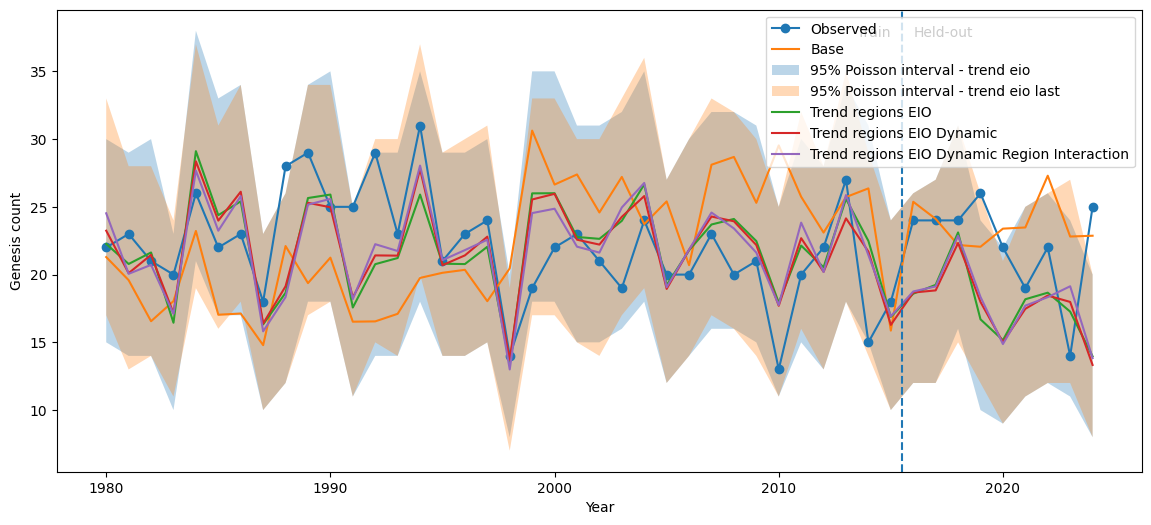

In [196]:
fig, ax = plt.subplots(figsize=(14, 6))
from scipy.stats import poisson

annual["base_low"] = poisson.ppf(
    0.025,
    annual["expected_base"],
)

annual["base_high"] = poisson.ppf(
    0.975,
    annual["expected_base"],
)

# annual["smooth_low"] = poisson.ppf(
#     0.025,
#     annual["expected_smooth"],
# )

# annual["smooth_high"] = poisson.ppf(
#     0.975,
#     annual["expected_smooth"],
# )

# annual["trend_low"] = poisson.ppf(
#     0.05,
#     annual["expected_trend"],
# )

# annual["trend_high"] = poisson.ppf(
#     0.95,
#     annual["expected_trend"],
# )


# annual["trend_bis_low"] = poisson.ppf(
#     0.05,
#     annual["expected_trend_bis"],
# )

# annual["trend_bis_high"] = poisson.ppf(
#     0.95,
#     annual["expected_trend_bis"],
# )

annual["trend_eio_low"] = poisson.ppf(
    0.05,
    annual["expected_trend_eio"],
)

annual["trend_eio_high"] = poisson.ppf(
    0.95,
    annual["expected_trend_eio"],
)

annual["trend_eio_last_low"] = poisson.ppf(
    0.05,
    annual["expected_trend_eio_dyn_last"],
)

annual["trend_eio_last_high"] = poisson.ppf(
    0.95,
    annual["expected_trend_eio_dyn_last"],
)


ax.plot(
    annual["year"],
    annual["observed"],
    marker="o",
    label="Observed",
)

ax.plot(
    annual["year"],
    annual["expected_base"],
    label="Base",
)

# ax.fill_between(
#     annual["year"],
#     annual["smooth_low"],
#     annual["smooth_high"],
#     alpha=0.2,
#     label="95% Poisson interval",
# )


# ax.fill_between(
#     annual["year"],
#     annual["trend_low"],
#     annual["trend_high"],
#     alpha=0.3,
#     label="95% Poisson interval - trend",
# )


# ax.fill_between(
#     annual["year"],
#     annual["trend_bis_low"],
#     annual["trend_bis_high"],
#     alpha=0.3,
#     label="95% Poisson interval - trend bis",
# )

ax.fill_between(
    annual["year"],
    annual["trend_eio_low"],
    annual["trend_eio_high"],
    alpha=0.3,
    label="95% Poisson interval - trend eio",
)

ax.fill_between(
    annual["year"],
    annual["trend_eio_last_low"],
    annual["trend_eio_last_high"],
    alpha=0.3,
    label="95% Poisson interval - trend eio last",
)


# ax.plot(
#     annual["year"],
#     annual["expected_smooth"],
#     label="Smooth regions",
# )

# ax.plot(
#     annual["year"],
#     annual["expected_trend"],
#     label="Trend regions",
# )

# ax.plot(
#     annual["year"],
#     annual["expected_trend_bis"],
#     label="Trend regions W30",
# )

# ax.plot(
#     annual["year"],
#     annual["expected_trend_eio_sstg"],
#     label="Trend regions EIO+SSTG",
# )

ax.plot(
    annual["year"],
    annual["expected_trend_eio"],
    label="Trend regions EIO",
)

ax.plot(
    annual["year"],
    annual["expected_trend_eio_dyn"],
    label="Trend regions EIO Dynamic",
)

ax.plot(
    annual["year"],
    annual["expected_trend_eio_dyn_last"],
    label="Trend regions EIO Dynamic Region Interaction",
)

# ax.plot(
#     annual["year"],
#     annual["expected_trend_sstg"],
#     label="Trend regions SSTG",
# )

ax.axvline(
    CFG.first_test_year - 0.5,
    linestyle="--",
)

ax.text(
    CFG.first_test_year - 1,
    ax.get_ylim()[1] * 0.95,
    "Train",
    ha="right",
)

ax.text(
    CFG.first_test_year,
    ax.get_ylim()[1] * 0.95,
    "Held-out",
    ha="left",
)

ax.set_xlabel("Year")
ax.set_ylabel("Genesis count")
ax.legend()

plt.show()


In [153]:
extreme_annual = annual.loc[(annual["observed"] >= annual["trend_eio_high"]) | (annual["observed"] <= annual["trend_eio_low"]), :]

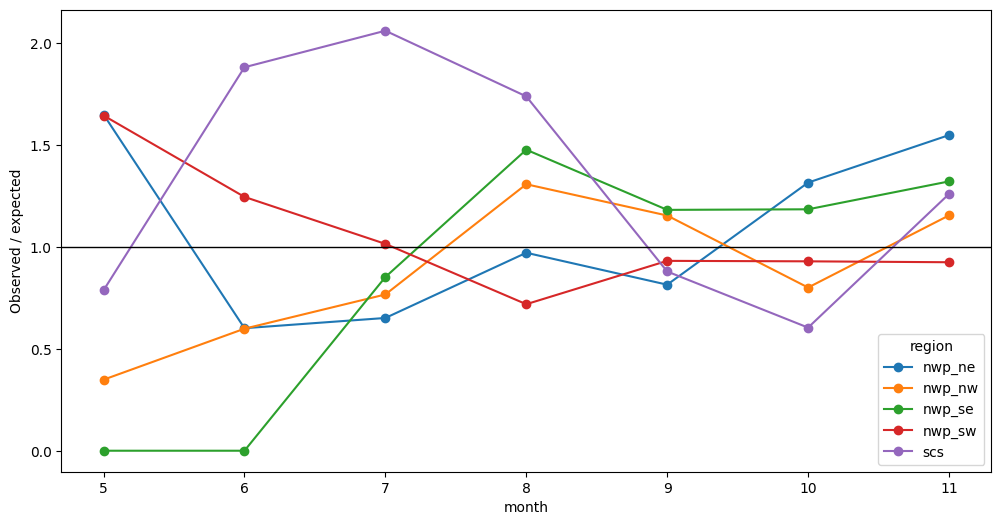

In [179]:
regional_month = historical_soft.groupby(["region", "month"], as_index=False).agg(
    observed=("genesis_count", "sum"),
    expected=("mu_trend_eio", "sum"),
)

regional_month["ratio"] = regional_month["observed"] / regional_month["expected"]

regional_month.pivot(
    index="month",
    columns="region",
    values="ratio",
).plot(
    marker="o",
    figsize=(12, 6),
)

plt.axhline(1, color="black", linewidth=1)
plt.ylabel("Observed / expected")
plt.show()


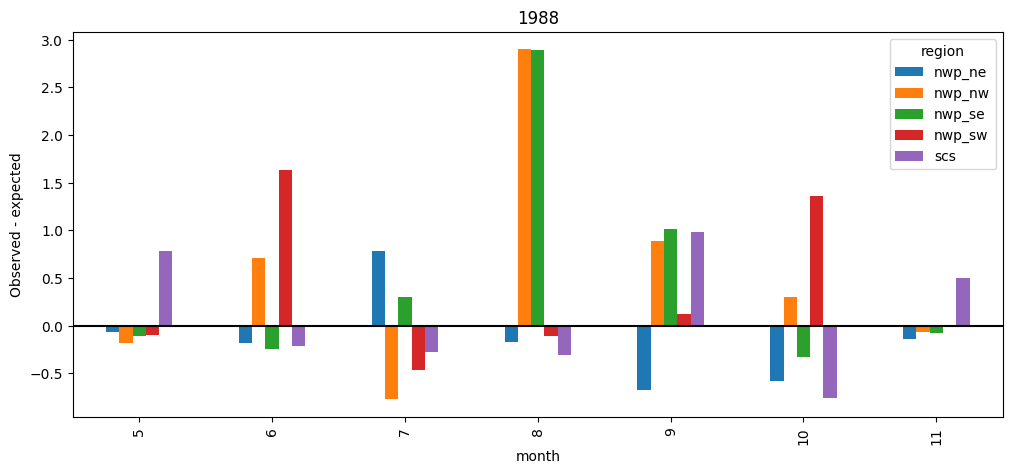

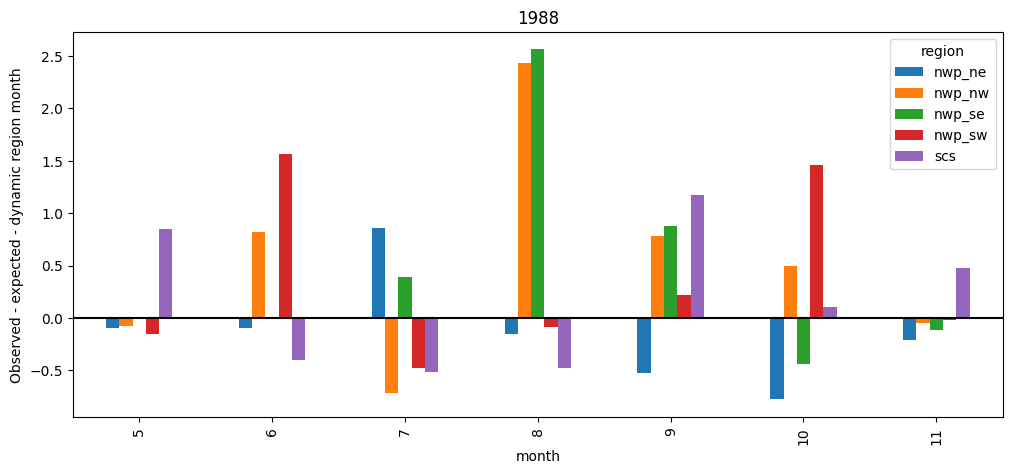

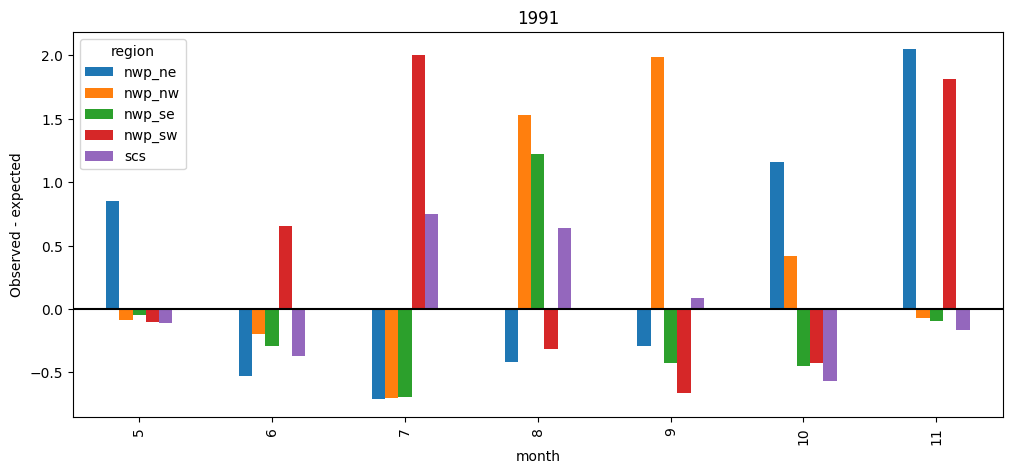

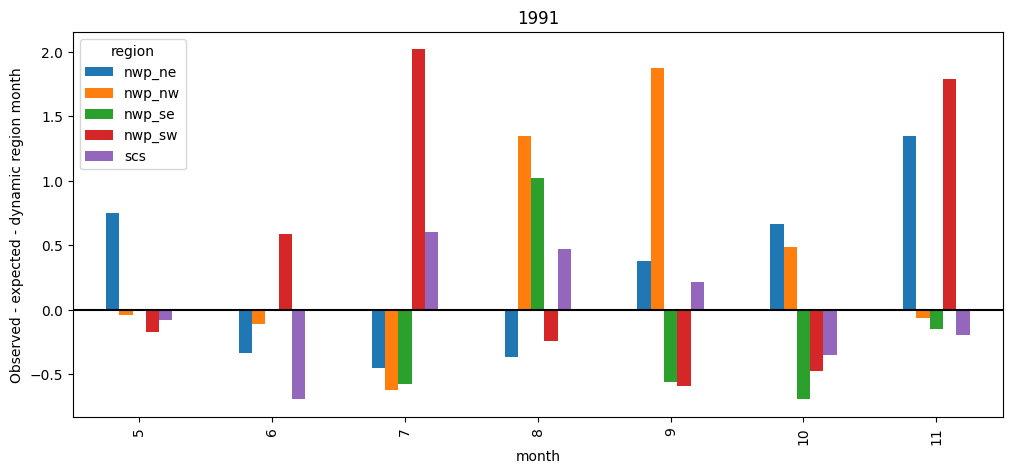

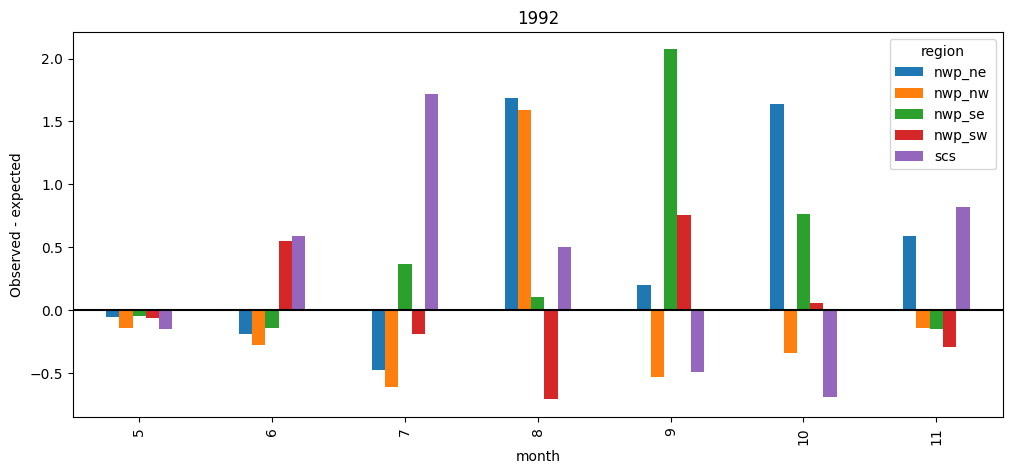

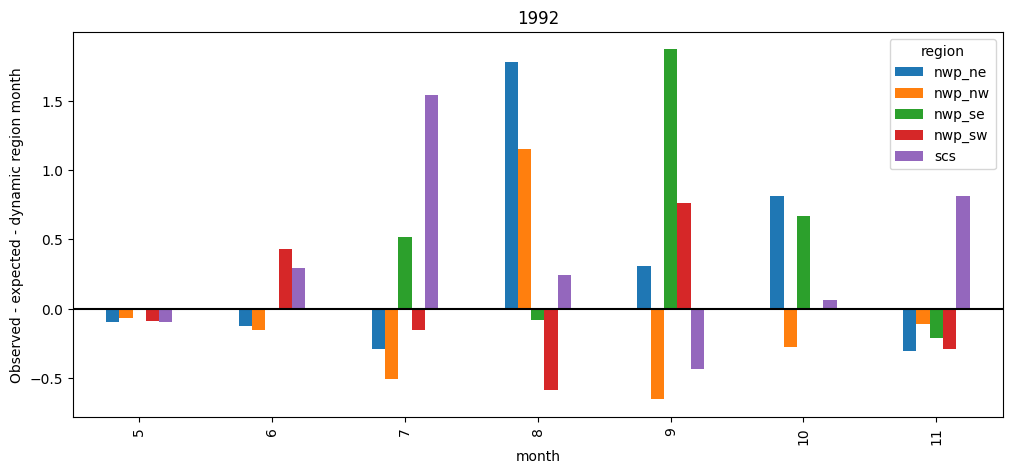

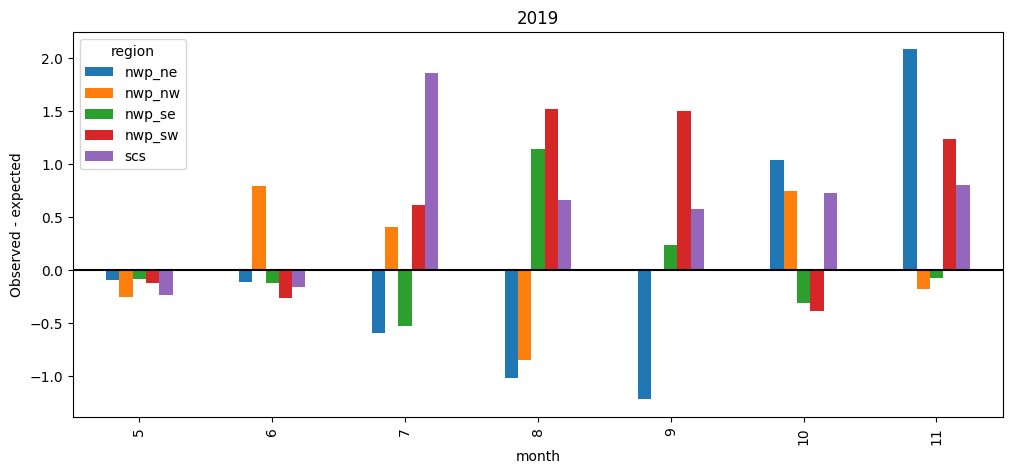

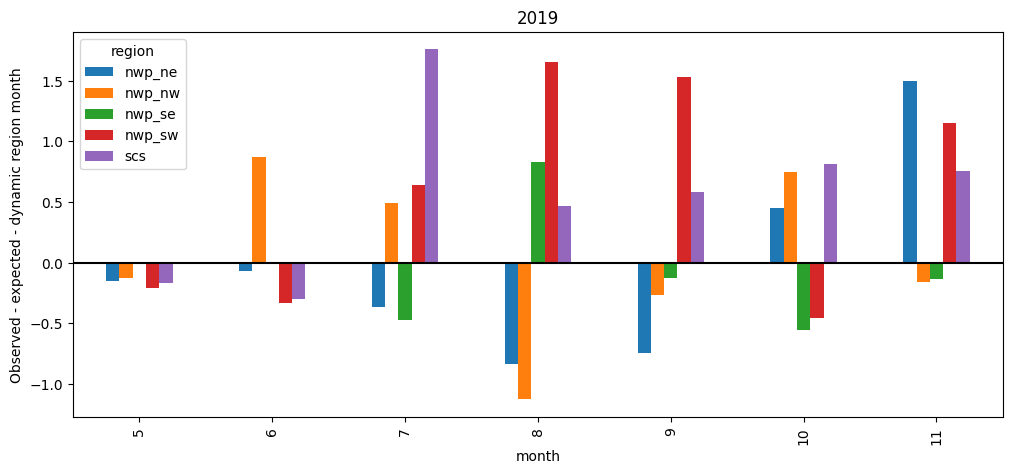

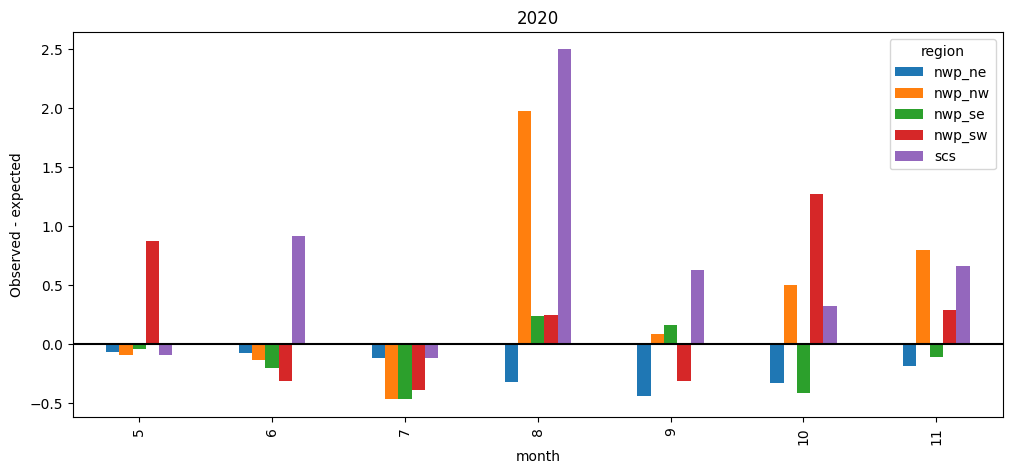

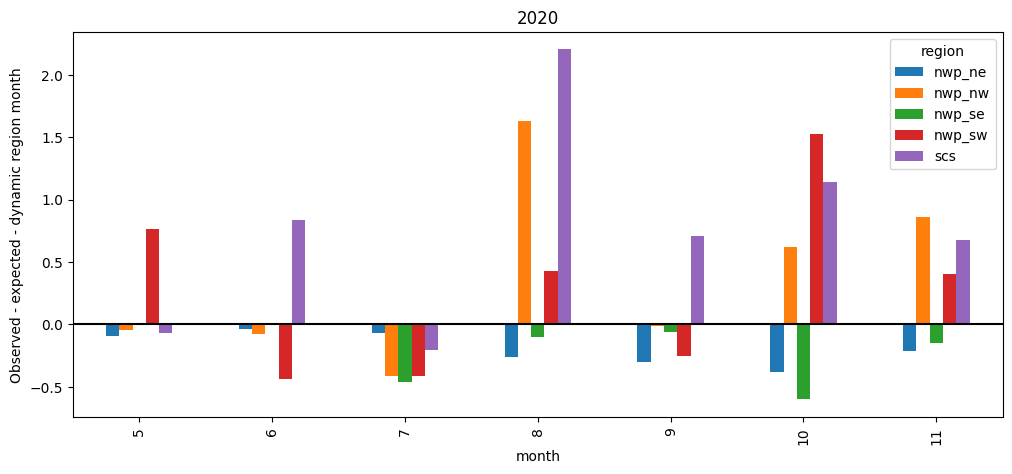

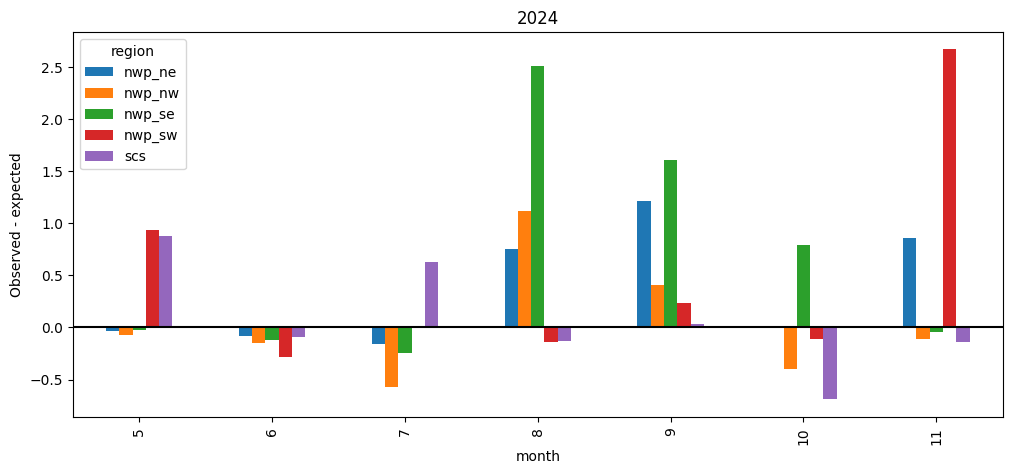

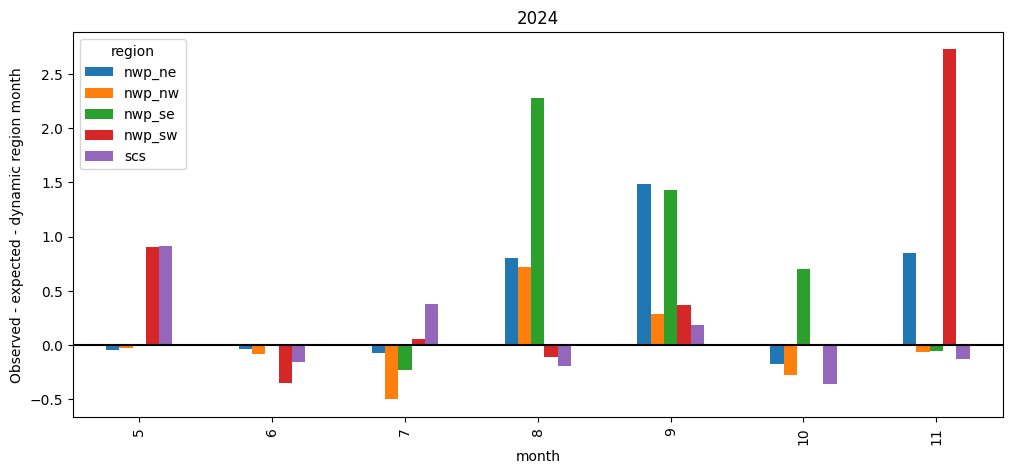

In [198]:
EXTREME_YEARS = [
    1988,
    1991,
    1992,
    2019,
    2020,
    2024,
]

extreme = (
    historical_soft[historical_soft["year"].isin(EXTREME_YEARS)]
    .groupby(
        ["year", "month", "region"],
        as_index=False,
    )
    .agg(
        observed=("genesis_count", "sum"),
        expected_dyn_reg_month=("mu_trend_eio_dyn_last", "sum"),
        expected=("mu_trend_eio", "sum"),
                        
    )
)

extreme["resid"] = extreme["observed"] - extreme["expected"]
extreme["resid_dyn_reg_month"] = extreme["observed"] - extreme["expected_dyn_reg_month"]

for year in EXTREME_YEARS:
    x = extreme[extreme["year"] == year].pivot(
        index="month",
        columns="region",
        values="resid",
    )

    x.plot(
        kind="bar",
        figsize=(12, 5),
        title=str(year),
    )

    plt.axhline(0, color="black")
    plt.ylabel("Observed - expected")
    plt.show()


    x = extreme[extreme["year"] == year].pivot(
        index="month",
        columns="region",
        values="resid_dyn_reg_month",
    )

    x.plot(
        kind="bar",
        figsize=(12, 5),
        title=str(year),
    )

    plt.axhline(0, color="black")
    plt.ylabel("Observed - expected - dynamic region month")
    plt.show()

In [156]:
genesis.loc[genesis["year"].isin(extreme_annual["year"])]

,stormid,time,latitude,longitude,speed,time_month,year,month,ilat,ilon,cell_lat,cell_lon,region
672,917,1988-05-01,18.299999,119.199997,20.577776,1988-05-01,1988,5,41,19,18.5,119.5,scs
673,919,1988-06-01,20.400000,123.400002,18.005554,1988-06-01,1988,6,39,23,20.5,123.5,nwp_nw
675,924,1988-06-01,9.400000,132.399994,18.005554,1988-06-01,1988,6,50,32,9.5,132.5,nwp_sw
677,926,1988-06-01,9.200000,127.699997,18.005554,1988-06-01,1988,6,50,27,9.5,127.5,nwp_sw
679,930,1988-07-01,12.300000,141.300003,18.005554,1988-07-01,1988,7,47,41,12.5,141.5,nwp_ne
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3705,4786,2024-10-01,13.500000,145.899994,18.005554,2024-10-01,2024,10,46,45,13.5,145.5,nwp_ne
3706,4788,2024-11-01,10.800000,136.199997,18.005554,2024-11-01,2024,11,49,36,10.5,136.5,nwp_sw
3709,4792,2024-11-01,14.500000,131.500000,18.005554,2024-11-01,2024,11,45,31,14.5,131.5,nwp_sw
3710,4793,2024-11-01,12.600000,161.800003,18.005554,2024-11-01,2024,11,47,61,12.5,161.5,nwp_ne


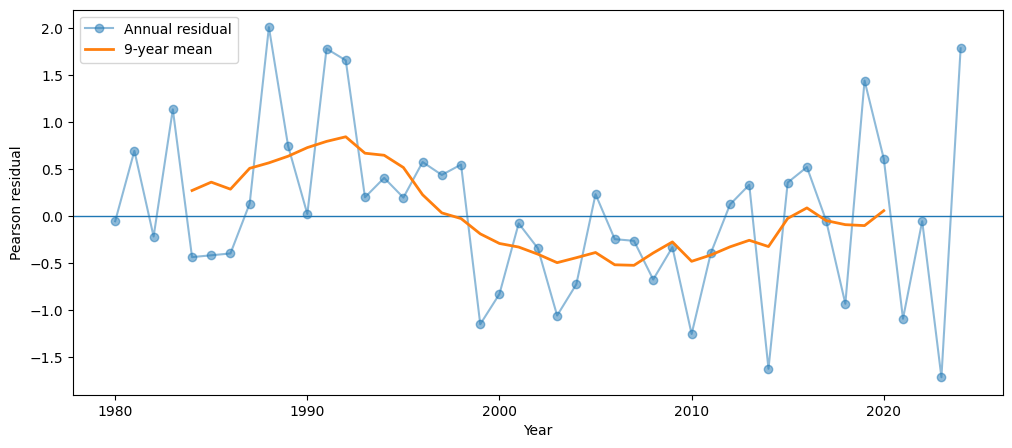

In [44]:
annual["resid"] = annual["observed"] - annual["expected_trend_eio"]

annual["pearson_resid"] = (annual["observed"] - annual["expected_trend_eio"]) / np.sqrt(
    annual["expected_trend_eio"]
)

annual["resid_lowfreq"] = annual["pearson_resid"].rolling(9, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 5))

ax.axhline(0, linewidth=1)

ax.plot(
    annual["year"],
    annual["pearson_resid"],
    marker="o",
    alpha=0.5,
    label="Annual residual",
)

ax.plot(
    annual["year"],
    annual["resid_lowfreq"],
    linewidth=2,
    label="9-year mean",
)

ax.set_ylabel("Pearson residual")
ax.set_xlabel("Year")
ax.legend()


In [45]:
from statsmodels.tsa.stattools import acf

acf_vals = acf(
    annual["pearson_resid"].dropna(),
    nlags=10,
    fft=False,
)

print(acf_vals)


[ 1.          0.08755044  0.04645526  0.12572753  0.26370217  0.13560044
 -0.0261923   0.06977132  0.03247853  0.05938366 -0.0671859 ]


     year region  observed  expected
0    1980     NE         7  6.122034
1    1980     NW         2  3.085937
2    1980    SCS         4  4.951869
3    1980     SE         5  2.809781
4    1980     SW         4  5.297121
..    ...    ...       ...       ...
220  2024     NE         5  2.668265
221  2024     NW         4  4.680530
222  2024    SCS         3  3.504715
223  2024     SE         6  2.322096
224  2024     SW         7  4.360471

[225 rows x 4 columns]
Regional Pearson residuals:
region        NE        NW       SCS        SE        SW
year                                                    
1980    0.354838 -0.618174 -0.427753  1.306626 -0.563586
1981    1.185699 -0.113174 -0.232346  1.716119 -0.717467
1982   -0.175627 -0.227037 -0.112425 -0.995198  0.964970
1983    1.886471  0.096628  1.165464  0.034800 -0.422224
1984    1.642297 -0.356012  0.171653  0.339834 -2.250561


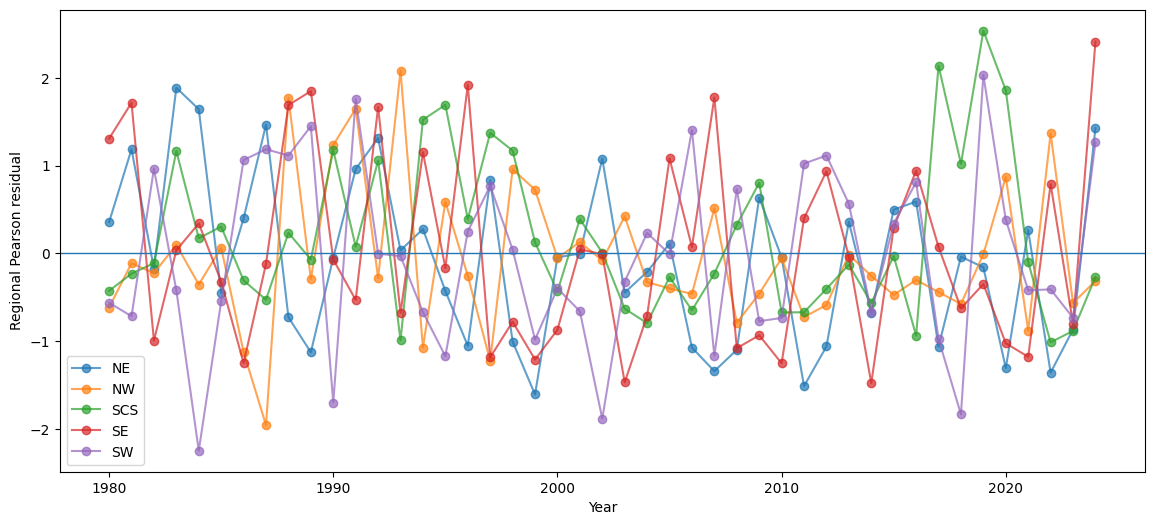

In [47]:
region_cols = [
    "w_nwp_ne",
    "w_nwp_nw",
    "w_nwp_se",
    "w_nwp_sw",
    "w_scs",
]

region_names = {
    "w_nwp_ne": "NE",
    "w_nwp_nw": "NW",
    "w_nwp_se": "SE",
    "w_nwp_sw": "SW",
    "w_scs": "SCS",
}

historical_soft["region"] = (
    historical_soft[region_cols].idxmax(axis=1).map(region_names)
)
regional_annual = historical_soft.groupby(["year", "region"], as_index=False).agg(
    observed=("genesis_count", "sum"),
    expected=("mu_trend_eio", "sum"),
)

print(regional_annual)

regional_annual["pearson"] = (
    regional_annual["observed"] - regional_annual["expected"]
) / np.sqrt(regional_annual["expected"])

resid_matrix = regional_annual.pivot(
    index="year",
    columns="region",
    values="pearson",
)

print("Regional Pearson residuals:")
print(resid_matrix.head())

fig, ax = plt.subplots(figsize=(14, 6))

for region in resid_matrix.columns:
    ax.plot(
        resid_matrix.index,
        resid_matrix[region],
        marker="o",
        alpha=0.7,
        label=region,
    )

ax.axhline(0, linewidth=1)

ax.set_xlabel("Year")
ax.set_ylabel("Regional Pearson residual")
ax.legend()

plt.show()

In [48]:
resid_matrix.corr()


region,NE,NW,SCS,SE,SW
region,,,,,
NE,1.000000,-0.254630,0.040096,0.105555,-0.076581
NW,-0.254630,1.000000,0.031349,0.006751,-0.097408
SCS,0.040096,0.031349,1.000000,-0.052714,-0.112322
SE,0.105555,0.006751,-0.052714,1.000000,0.113202
SW,-0.076581,-0.097408,-0.112322,0.113202,1.000000


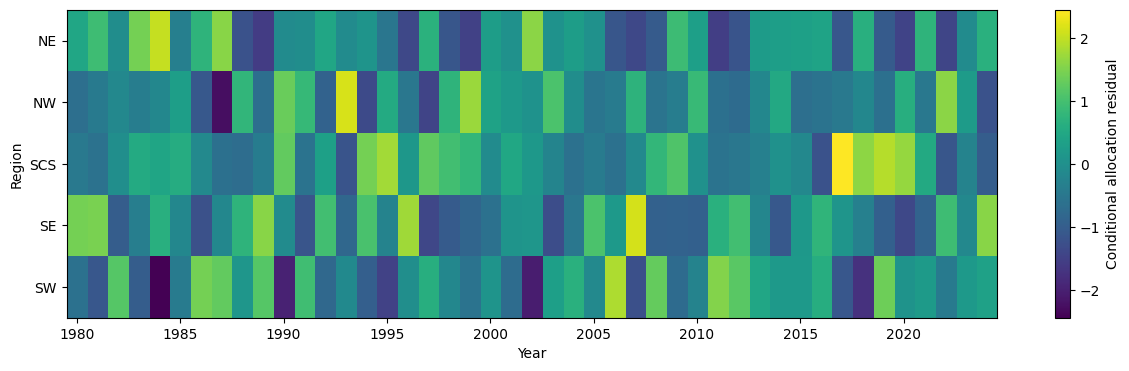

In [50]:
annual_totals = regional_annual.groupby("year", as_index=False).agg(
    observed_total=("observed", "sum"),
    expected_total=("expected", "sum"),
)

regional_diag = regional_annual.merge(
    annual_totals,
    on="year",
    how="left",
)

regional_diag["p_expected"] = (
    regional_diag["expected"] / regional_diag["expected_total"]
)

regional_diag["observed_given_total"] = regional_diag["observed"]

regional_diag["expected_given_total"] = (
    regional_diag["observed_total"] * regional_diag["p_expected"]
)
p = regional_diag["p_expected"]
n = regional_diag["observed_total"]

var_multinomial = n * p * (1 - p)

regional_diag["allocation_resid"] = (
    regional_diag["observed"] - regional_diag["expected_given_total"]
) / np.sqrt(var_multinomial.clip(lower=1e-8))

annual_totals["activity_resid"] = (
    annual_totals["observed_total"] - annual_totals["expected_total"]
) / np.sqrt(annual_totals["expected_total"])

allocation_matrix = regional_diag.pivot(
    index="region",
    columns="year",
    values="allocation_resid",
)

fig, ax = plt.subplots(figsize=(15, 4))

im = ax.imshow(
    allocation_matrix,
    aspect="auto",
    interpolation="nearest",
)

ax.set_yticks(np.arange(len(allocation_matrix.index)))
ax.set_yticklabels(allocation_matrix.index)

ax.set_xticks(np.arange(len(allocation_matrix.columns))[::5])
ax.set_xticklabels(allocation_matrix.columns[::5])

ax.set_xlabel("Year")
ax.set_ylabel("Region")

plt.colorbar(
    im,
    ax=ax,
    label="Conditional allocation residual",
)

plt.show()

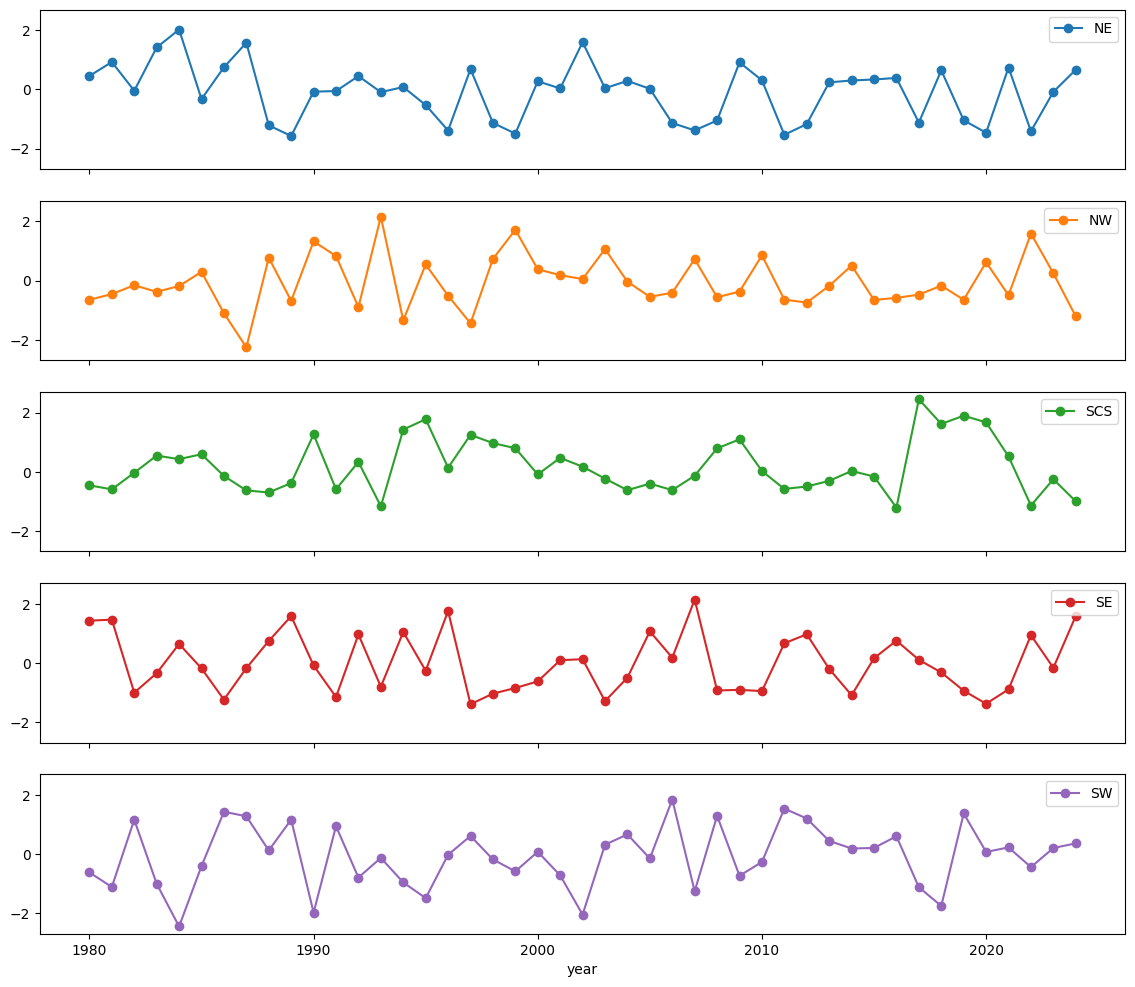

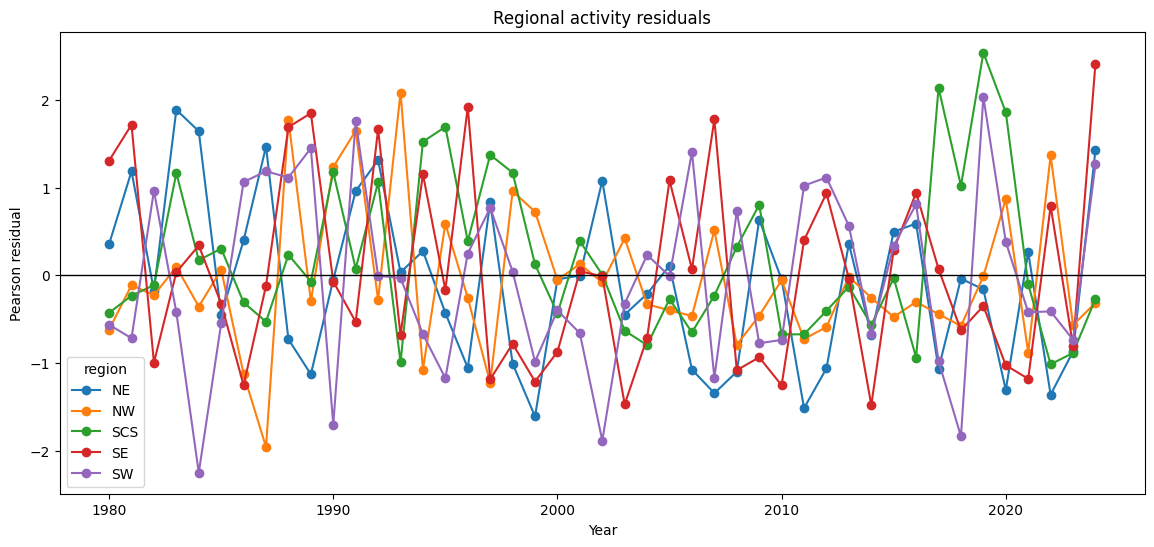

In [62]:
regional_diag.pivot(
    index="year",
    columns="region",
    values="allocation_resid",
).plot(
    subplots=True,
    figsize=(14, 12),
    sharex=True,
    sharey=True,
    marker="o",
)

plt.show()

regional_annual.pivot(
    index="year",
    columns="region",
    values="pearson",
).plot(
    figsize=(14, 6),
    marker="o",
)

plt.axhline(0, color="black", linewidth=1)

plt.xlabel("Year")
plt.ylabel("Pearson residual")
plt.title("Regional activity residuals")

plt.show()


In [63]:
activity_matrix = regional_annual.pivot(
    index="year",
    columns="region",
    values="pearson",
)

print(activity_matrix.corr())


region        NE        NW       SCS        SE        SW
region                                                  
NE      1.000000 -0.254630  0.040096  0.105555 -0.076581
NW     -0.254630  1.000000  0.031349  0.006751 -0.097408
SCS     0.040096  0.031349  1.000000 -0.052714 -0.112322
SE      0.105555  0.006751 -0.052714  1.000000  0.113202
SW     -0.076581 -0.097408 -0.112322  0.113202  1.000000


In [64]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = activity_matrix.dropna()

Xz = StandardScaler().fit_transform(X)

pca = PCA().fit(Xz)

loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=[f"PC{i + 1}" for i in range(len(X.columns))],
)

print(pca.explained_variance_ratio_)
print(loadings)


[0.25684832 0.23634983 0.19634683 0.17970821 0.13074681]
             PC1       PC2       PC3       PC4       PC5
region                                                  
NE     -0.618851 -0.407488  0.150383 -0.199094  0.623477
NW      0.647237  0.147474  0.443104 -0.159824  0.580906
SCS     0.145088 -0.551035  0.308219  0.760287 -0.047691
SE     -0.340053  0.324248  0.813755 -0.051212 -0.338242
SW     -0.247835  0.635160 -0.154427  0.595112  0.396413


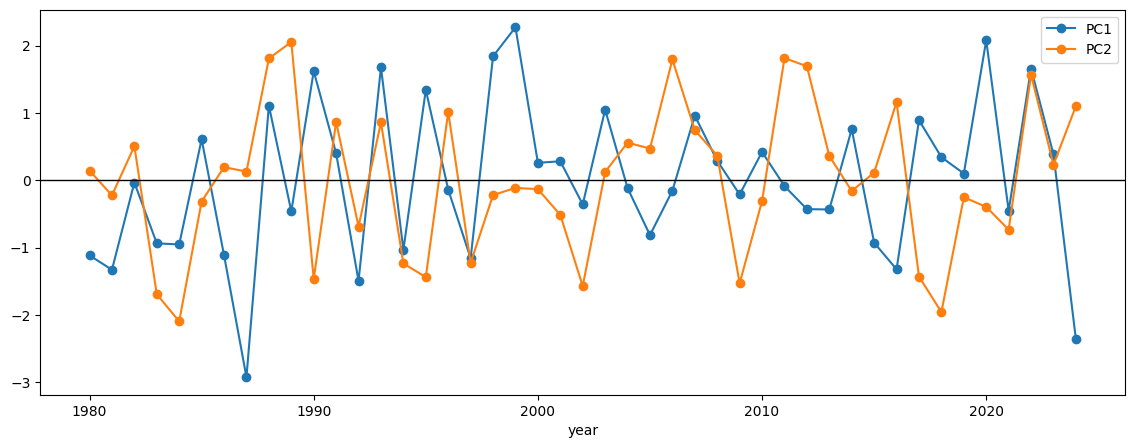

In [65]:
scores = pca.transform(Xz)

pc = pd.DataFrame(
    scores[:, :2],
    index=X.index,
    columns=["PC1", "PC2"],
)

pc.plot(
    figsize=(14, 5),
    marker="o",
)

plt.axhline(0, color="black", linewidth=1)
plt.show()


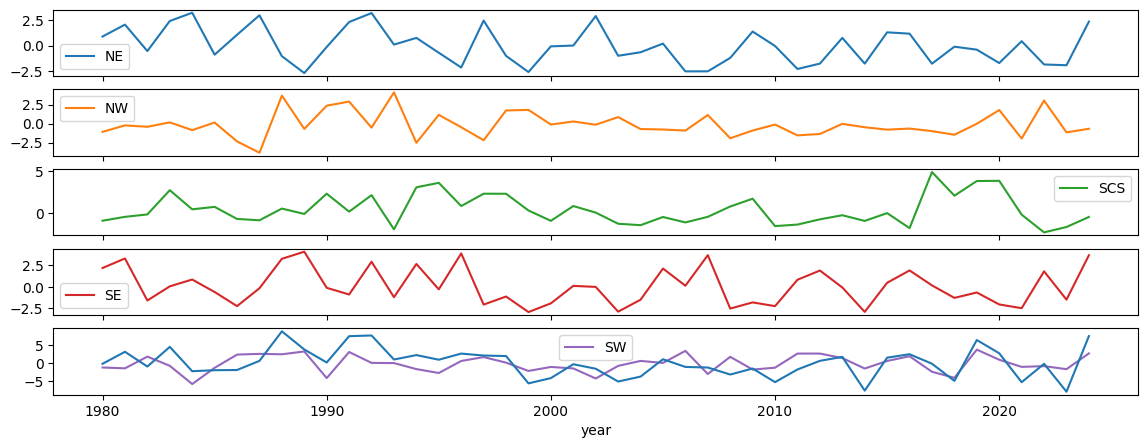

In [74]:
regional_annual["count_resid"] = (
    regional_annual["observed"] - regional_annual["expected"]
)

regional_count = regional_annual.pivot(
    index="year",
    columns="region",
    values="count_resid",
)

regional_count.plot(
    subplots=True,
    figsize=(14, 12),
    sharex=True,
)
regional_count["TOTAL"] = regional_count.sum(axis=1)
regional_count["TOTAL"].plot(sharey=False,figsize=(14, 5))

plt.show()


<Axes: xlabel='year'>

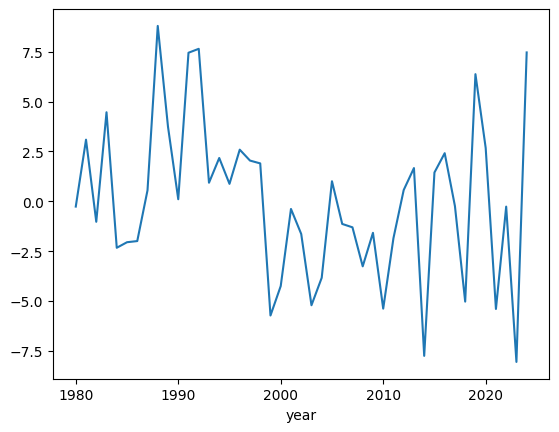

In [69]:
regional_count["TOTAL"].plot()



In [81]:
annual_test = annual[annual["year"] >= CFG.first_test_year].copy()
annual_train = annual[annual["year"] < CFG.first_test_year].copy()
def annual_metrics(df, expected_col):

    obs = df["observed"].to_numpy()
    pred = df[expected_col].to_numpy()

    return {
        "mean_observed": obs.mean(),
        "mean_expected": pred.mean(),
        "bias": (pred - obs).mean(),
        "mae": np.mean(np.abs(pred - obs)),
        "rmse": np.sqrt(np.mean((pred - obs) ** 2)),
        "correlation": np.corrcoef(
            obs,
            pred,
        )[0, 1],
        "poisson_log_score": poisson.logpmf(
            obs,
            np.clip(pred, 1e-12, None),
        ).sum(),
    }

b = pd.DataFrame(
    {
        "base": annual_metrics(
            annual_test,
            "expected_base",
        ),
        "smooth": annual_metrics(
            annual_test,
            "expected_smooth",
        ),
        "trend": annual_metrics(
            annual_test,
            "expected_trend",
        ),
        "trend_bis": annual_metrics(
            annual_test,
            "expected_trend_bis",
        ),
        "eio": annual_metrics(
            annual_test,
            "expected_trend_eio",
        ),
        "sstg": annual_metrics(
            annual_test,
            "expected_trend_sstg",
        ),
        "eio_sstg": annual_metrics(
            annual_test,
            "expected_trend_eio_sstg",
        ),
    }
)
b

,base,smooth,trend,trend_bis,eio,sstg,eio_sstg
mean_observed,22.222222,22.222222,22.222222,22.222222,22.222222,22.222222,22.222222
mean_expected,23.729951,22.100756,22.100756,22.154048,22.230542,22.137531,22.137531
bias,1.507728,-0.121466,-0.121466,-0.068175,0.008320,-0.084691,-0.084691
mae,3.261783,2.526070,2.526070,2.558744,4.213779,4.270300,4.270300
rmse,4.122858,3.344908,3.344908,3.388579,5.042338,5.051926,5.051926
correlation,-0.004194,0.295530,0.295530,0.239685,-0.131687,-0.376024,-0.376024
poisson_log_score,-25.760533,-24.676008,-24.676008,-24.736126,-27.647083,-27.580568,-27.580568


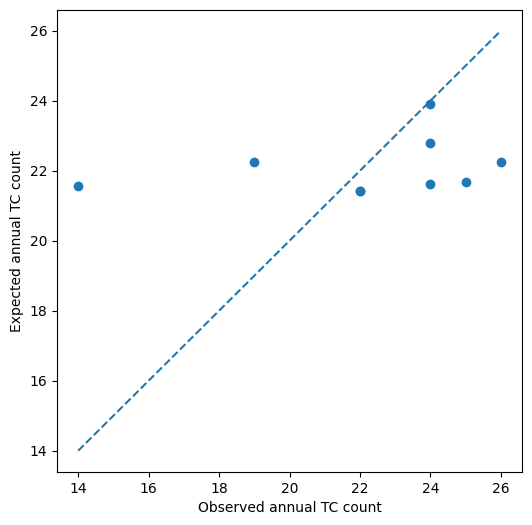

In [37]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    annual_test["observed"],
    annual_test["expected_smooth"],
)

lo = min(
    annual_test["observed"].min(),
    annual_test["expected_smooth"].min(),
)

hi = max(
    annual_test["observed"].max(),
    annual_test["expected_smooth"].max(),
)

ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
)

ax.set_xlabel("Observed annual TC count")
ax.set_ylabel("Expected annual TC count")

plt.show()


In [77]:
def annual_variability(df, col):

    x = df[col].to_numpy()

    return {
        "mean": x.mean(),
        "std": x.std(ddof=1),
        "variance": x.var(ddof=1),
        "CV": x.std(ddof=1) / x.mean(),
    }

a = pd.DataFrame(
    {
        "observed_test": annual_variability(
            annual_test,
            "observed",
        ),
        "base_test": annual_variability(
            annual_test,
            "expected_base",
        ),
        "smooth_test": annual_variability(
            annual_test,
            "expected_smooth",
        ),
        "trend_test": annual_variability(
            annual_test,
            "expected_trend",
        ),
        "trend_bis_test": annual_variability(
            annual_test,
            "expected_trend_bis",
        ),
        "eio_test": annual_variability(
            annual_test,
            "expected_trend_eio",
        ),
        "sstg_test": annual_variability(
            annual_test,
            "expected_trend_sstg",
        ),
        "eio_sstg_test": annual_variability(
            annual_test,
            "expected_trend_eio_sstg",
        ),
        "observed_train": annual_variability(
            annual_train,
            "observed",
        ),
        "base_train": annual_variability(
            annual_train,
            "expected_base",
        ),
        "smooth_train": annual_variability(
            annual_train,
            "expected_smooth",
        ),
        "trend_train": annual_variability(
            annual_train,
            "expected_trend",
        ),
        "trend_bis_train": annual_variability(
            annual_train,
            "expected_trend_bis",
        ),
        "eio_train": annual_variability(
            annual_train,
            "expected_trend_eio",
        ),
        "sstg_train": annual_variability(
            annual_train,
            "expected_trend_sstg",
        ),
        "eio_sstg_train": annual_variability(
            annual_train,
            "expected_trend_eio_sstg",
        ),
    }
)
a

,observed_test,base_test,smooth_test,trend_test,trend_bis_test,eio_test,sstg_test,eio_sstg_test,observed_train,base_train,smooth_train,trend_train,trend_bis_train,eio_train,sstg_train,eio_sstg_train
mean,22.222222,23.729951,22.100756,22.100756,22.154048,22.230542,22.137531,22.137531,22.055556,22.055556,22.055556,22.055556,22.055556,22.055556,22.055556,22.055556
std,3.700601,1.678913,0.825375,0.825375,0.817460,3.404502,2.725037,2.725037,3.985290,4.421713,2.598622,2.598622,2.583058,3.611096,3.592552,3.592552
variance,13.694444,2.818748,0.681243,0.681243,0.668240,11.590637,7.425825,7.425825,15.882540,19.551542,6.752839,6.752839,6.672189,13.040012,12.906429,12.906429
CV,0.166527,0.070751,0.037346,0.037346,0.036899,0.153145,0.123096,0.123096,0.180693,0.200481,0.117822,0.117822,0.117116,0.163727,0.162886,0.162886


In [ ]:
FORMULA_SOFT_REGION_MONTH


glm_soft = smf.glm(
    formula=FORMULA_SOFT_REGION_MONTH,
    data=train_soft,
    family=sm.families.Poisson(),
    offset=train_soft["log_exposure"],
)

X = glm_soft.exog

s = np.linalg.svd(X, compute_uv=False)

print("n parameters:", X.shape[1])
print("rank:", np.linalg.matrix_rank(X))
print("condition number:", s[0] / s[-1])
print("smallest singular values:", s[-10:])


n parameters: 35
rank: 35
condition number: 79.50037286432932
smallest singular values: [59.73667643 59.21112268 48.4069315  42.66876876 42.66702764 42.65891658
 42.47778014 27.99351431 22.58321521 16.28166024]


In [104]:
comparison = pd.DataFrame(
    [
        evaluate_model(
            "Environmental",
            m_base,
            test_eta,
        ),
        evaluate_model(
            "Environmental + Varying",
            m_varying,
            test_eta,
        ),
        evaluate_model(
            "Environmental + PI varying",
            m_pi_varying,
            test_eta,
        ),
        evaluate_model(
            "Environmental + full varying",
            m_full_varying,
            test_eta,
        ),
        evaluate_model(
            "Environmental + Region x Month",
            m_region_month,
            test_soft,
        ),
        evaluate_model(
            "Environmental + Region Smoothed",
            m_soft_region_month,
            test_soft,
        ),
    ]
)

comparison


,model,cell_log_score,monthly_log_score,monthly_mean_log_score,monthly_bias,monthly_rmse
0,Environmental,-989.035467,-97.431665,-1.804290,-0.663761,1.643973
1,Environmental + Varying,-998.994512,-97.006342,-1.796414,-0.660954,1.622322
2,Environmental + PI varying,-988.299507,-97.249431,-1.800915,-0.656368,1.638474
3,Environmental + full varying,-1019.773843,-97.348131,-1.802743,-0.650020,1.625510
4,Environmental + Region x Month,-1097.425795,-98.447349,-1.823099,-0.632409,1.608732
5,Environmental + Region Smoothed,-974.187619,-95.628857,-1.770905,-0.624191,1.588167


In [39]:
# for name, model in {
#     "base": m_base,
#     "pi_varying": m_pi_varying,
#     "all_varying": m_varying,
#     "full_month": m_full_varying,
#     "region_month" : m_region_month,
#     "soft_region_month" : m_soft_region_month,
            
# }.items():
#     test_soft[f"mu_{name}"] = model.predict(
#         test_soft,
#         offset=test_soft["log_exposure"],
#     )


def spatial_month(df, month, column):
    d = df[df["month"] == month]

    return (
        d.groupby(
            ["latitude", "longitude"],
            as_index=False,
        )[column]
        .sum()
        .pivot(
            index="latitude",
            columns="longitude",
            values=column,
        )
    )


In [95]:
panama = test_soft["latitude"].between(8, 16) & test_soft["longitude"].between(275, 292)

diag = (
    test_soft.loc[panama]
    .groupby("month")
    .agg(
        observed=("genesis_count", "sum"),
        base=("mu_base", "sum"),
        pi_varying=("mu_pi_varying", "sum"),
        region_month=("mu_region_month", "sum"),
        soft_region_month=("mu_soft_region_month", "sum"),
        # full_varying=("mu_full_varying", "sum"),
    )
)

diag


,observed,base,pi_varying,region_month,soft_region_month
month,,,,,
6,0,0.961607,0.979078,1.302815e-10,0.118032
7,0,0.492730,0.501595,3.321629e-01,0.371162
8,0,1.526894,1.577311,1.219420e+00,0.767799
9,2,2.495703,2.510372,1.190983e+00,0.927688
10,2,3.165411,3.193004,2.879230e+00,2.674254
11,5,2.448268,2.658088,2.537877e+00,2.405067


In [62]:
historical

,valid_time,latitude,longitude,pi,vws,rh600,eta850,w500,isobaricInhPa,time,...,mu_m1,mu_m2,contrib_z_pi,contrib_z_vws,contrib_z_rh600,contrib_z_eta850,mu_base,mu_smooth,mu_trend,mu_trend_bis
0,1980-06-01,5.5,307.5,62.214638,6.527966,74.135757,0.000012,-0.050212,500.0,1980-06-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000104,0.000002,0.000003,0.000003
1,1980-06-01,5.5,308.5,64.556786,6.258497,74.159195,0.000011,-0.066386,500.0,1980-06-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000134,0.000003,0.000004,0.000004
2,1980-06-01,5.5,309.5,64.749542,5.969858,74.024429,0.000011,-0.060649,500.0,1980-06-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000137,0.000003,0.000003,0.000003
3,1980-06-01,5.5,310.5,65.322342,6.057087,74.127945,0.000011,-0.057414,500.0,1980-06-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000143,0.000003,0.000003,0.000003
4,1980-06-01,5.5,311.5,65.222267,6.044542,73.700211,0.000011,-0.051372,500.0,1980-06-01,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000140,0.000003,0.000003,0.000003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1014847,2025-11-01,59.5,355.5,22.557652,9.098246,50.960861,0.000050,-0.013926,500.0,2025-11-01,...,0.000059,0.000053,-1.275386,0.316850,0.384815,0.427546,0.000059,0.000043,0.000046,0.000046
1014848,2025-11-01,59.5,356.5,21.760685,9.009826,52.716721,0.000050,-0.010569,500.0,2025-11-01,...,0.000060,0.000051,-1.333020,0.323459,0.484959,0.427546,0.000060,0.000039,0.000041,0.000041
1014849,2025-11-01,59.5,357.5,21.429478,9.124449,53.687424,0.000050,-0.013743,500.0,2025-11-01,...,0.000061,0.000052,-1.356972,0.314892,0.540322,0.427546,0.000061,0.000039,0.000042,0.000042
1014850,2025-11-01,59.5,358.5,20.235909,9.368005,53.529221,0.000050,-0.019724,500.0,2025-11-01,...,0.000055,0.000050,-1.443288,0.296687,0.531299,0.427546,0.000055,0.000039,0.000042,0.000041


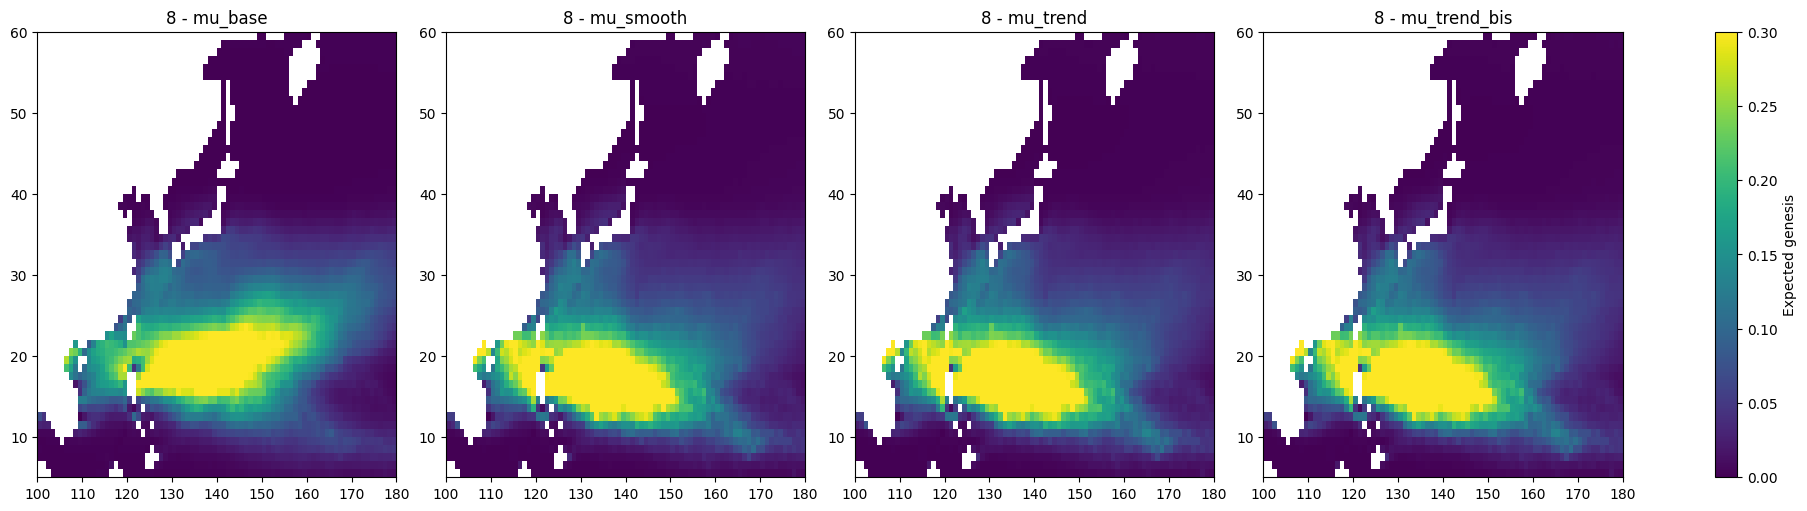

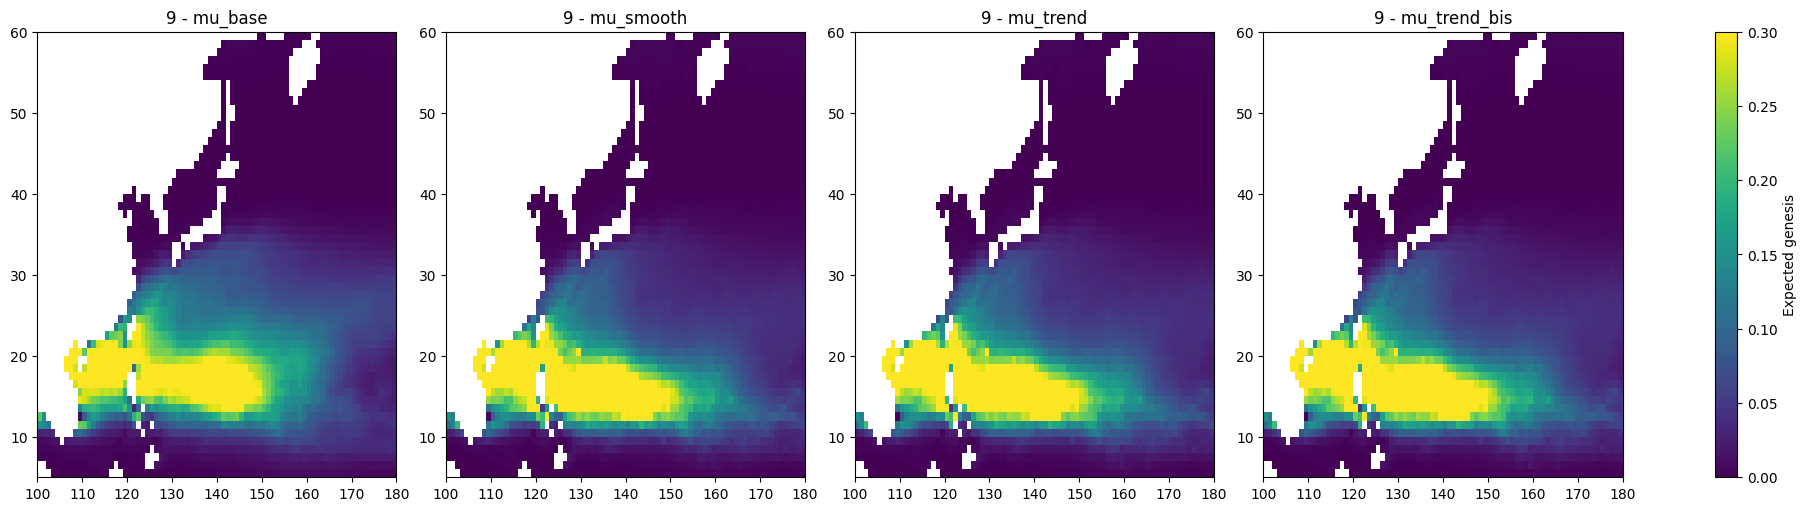

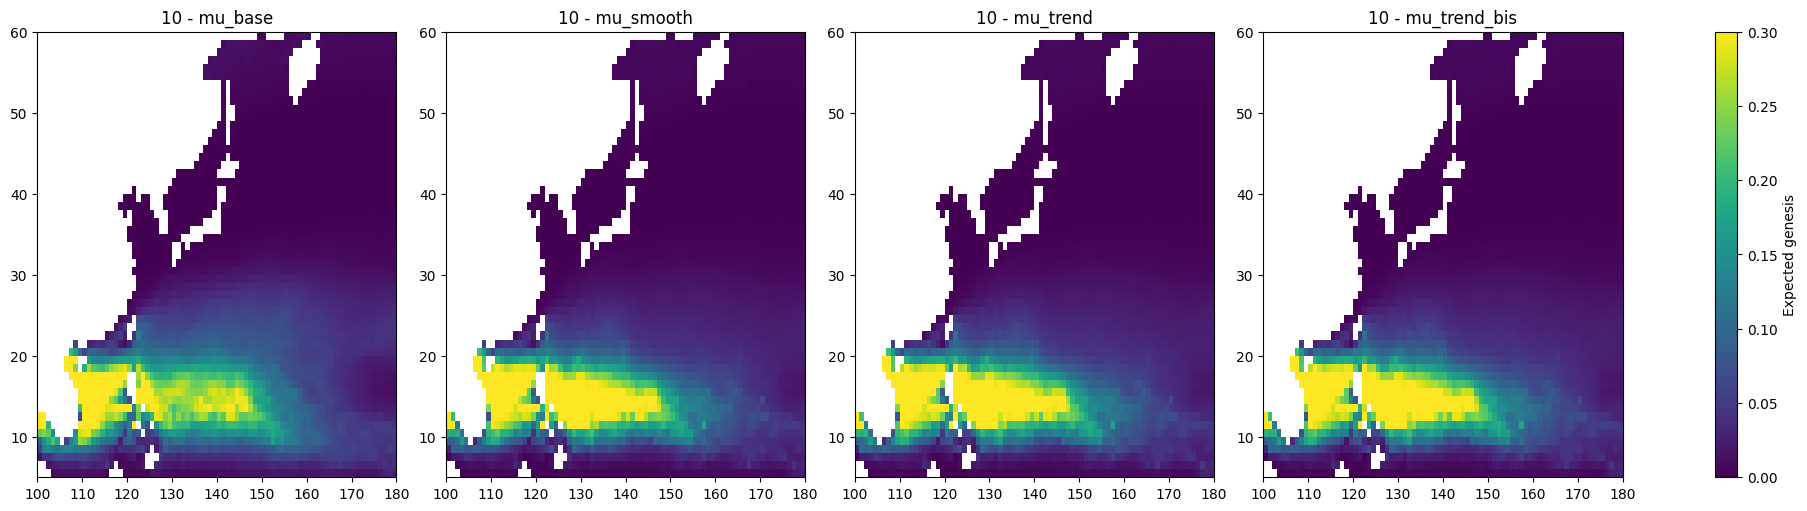

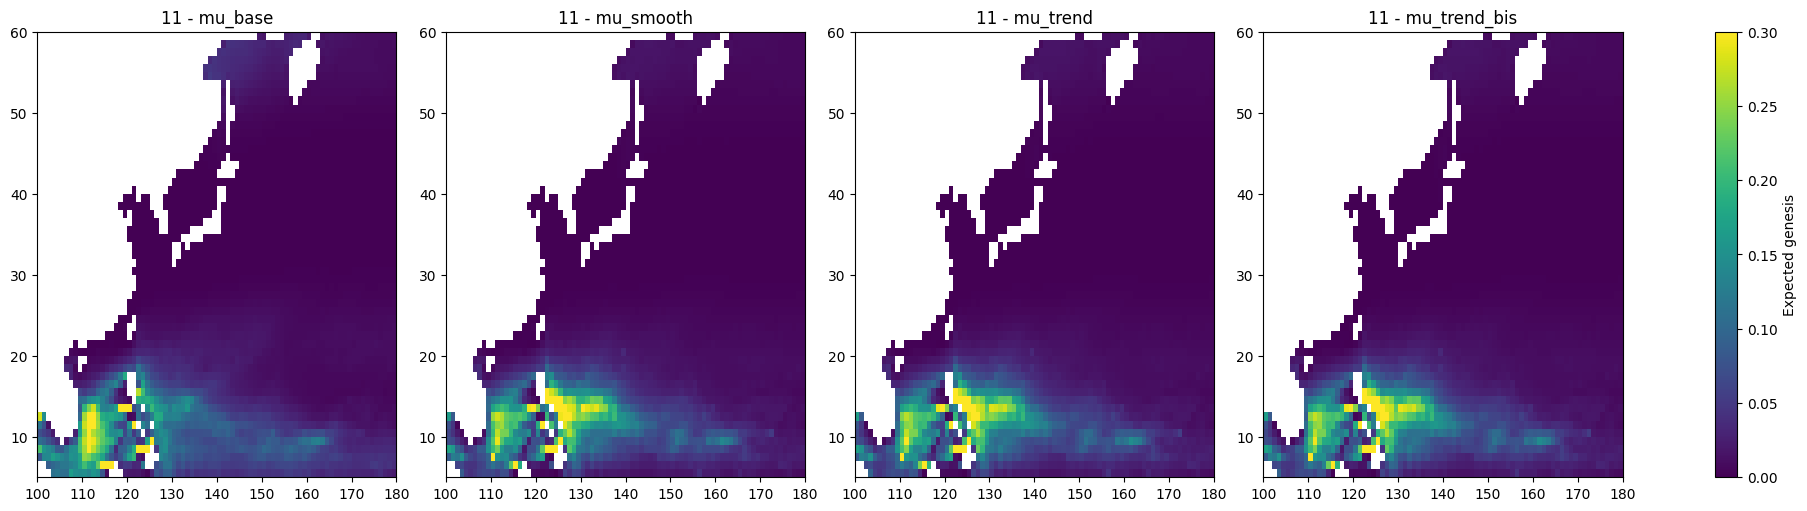

In [40]:
months = [8, 9, 10, 11]
models = [
    "mu_base",
    "mu_smooth",
    "mu_trend",
    "mu_trend_bis"
]

for month in months:
    fig, axes = plt.subplots(
        1,
        len(models),
        figsize=(18, 5),
        constrained_layout=True,
    )

    for ax, col in zip(axes, models):
        a = spatial_month(
            historical,
            month,
            col,
        )

        im = ax.pcolormesh(
            a.columns,
            a.index,
            a.values,
            shading="auto",
            vmin=0,
            vmax=0.3,  # adjust once, then keep common
        )

        ax.set_title(f"{month} - {col}")

    fig.colorbar(
        im,
        ax=axes,
        label="Expected genesis",
    )

    plt.show()


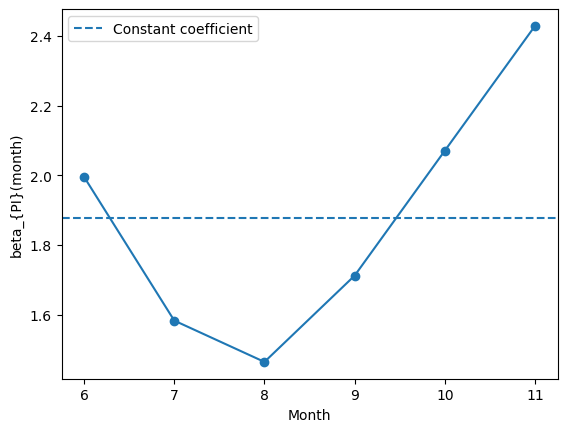

In [37]:
def monthly_partial_effect(
    model,
    variable,
    months=(6, 7, 8, 9, 10, 11),
    delta=0.01,
):
    rows = []

    for month in months:
        season_pos = MONTH_TO_POS[month]

        base = {
            "month": month,
            "season_pos": season_pos,
            "z_pi": 0.0,
            "z_rh600": 0.0,
            "z_vws": 0.0,
            "z_eta_clip": 0.0,
            "z_w500": 0.0,
            "log_exposure": 0.0,
        }

        low = base.copy()
        high = base.copy()

        low[variable] = -delta / 2
        high[variable] = +delta / 2

        low = pd.DataFrame([low])
        high = pd.DataFrame([high])

        loglam_low = np.log(model.predict(low, offset=[0])[0])

        loglam_high = np.log(model.predict(high, offset=[0])[0])

        beta = (loglam_high - loglam_low) / delta

        rows.append(
            {
                "month": month,
                "beta": beta,
            }
        )

    return pd.DataFrame(rows)


pi_effect = monthly_partial_effect(
    m_varying,
    "z_pi",
)

plt.plot(
    pi_effect["month"],
    pi_effect["beta"],
    marker="o",
)

plt.axhline(
    m_base.params["z_pi"],
    linestyle="--",
    label="Constant coefficient",
)

plt.ylabel(r"beta_{PI}(month)")
plt.xlabel("Month")
plt.legend()
plt.show()

In [69]:
best_eta_threshold = eta_scores.sort_values(
    "cell_log_score",
    ascending=False,
).iloc[0]["eta_threshold"]

best_eta_model, _, best_eta_test = eta_models[best_eta_threshold]

results.append(
    evaluate_model(
        f"Eta clipped {best_eta_threshold:.2e}",
        best_eta_model,
        best_eta_test,
    )
)

comparison = (
    pd.DataFrame(results)
    .sort_values(
        "cell_log_score",
        ascending=False,
    )
    .reset_index(drop=True)
)

comparison

,model,cell_log_score,monthly_log_score,monthly_mean_log_score,monthly_bias,monthly_rmse
0,PI + Eta splines,-986.549631,-97.546567,-1.806418,-0.669056,1.635158
1,Eta clipped 3.50e-05,-989.035467,-97.431665,-1.804290,-0.663761,1.643973
2,PI spline,-990.520634,-98.151908,-1.817628,-0.683923,1.645387
3,Eta spline,-995.844365,-98.189103,-1.818317,-0.679207,1.655370
4,linear,-1007.103385,-99.453082,-1.841724,-0.684900,1.667038


### Quantification

In [ ]:
print(m_linear.summary())
print(m_both_spline.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:          genesis_count   No. Observations:               794232
Model:                            GLM   Df Residuals:                   794222
Model Family:                 Poisson   Df Model:                            9
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2988.9
Date:                Fri, 25 Sep 2026   Deviance:                       5163.8
Time:                        15:32:12   Pearson chi2:                 6.26e+05
No. Iterations:                    10   Pseudo R-squ. (CS):           0.001125
Covariance Type:            nonrobust                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         -7.4005      0.244    -30.

In [122]:
print(m_soft_region_month.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:          genesis_count   No. Observations:               794232
Model:                            GLM   Df Residuals:                   794218
Model Family:                 Poisson   Df Model:                           13
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2954.4
Date:                Sun, 27 Sep 2026   Deviance:                       5094.9
Time:                        11:34:09   Pearson chi2:                 5.90e+05
No. Iterations:                    11   Pseudo R-squ. (CS):           0.001211
Covariance Type:            nonrobust                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept           -10.0164      0.47

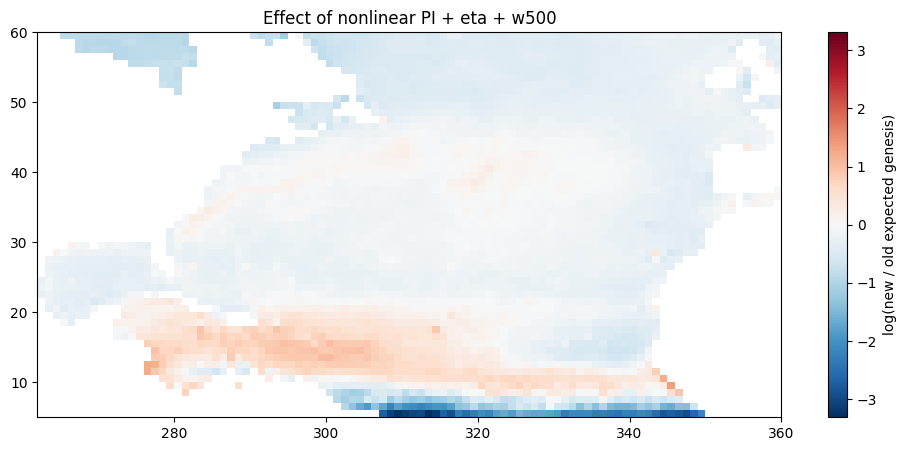

In [39]:
# Predictions from old and new models on exactly the same test rows
test_compare = test.copy()

test_compare["mu_old"] = m_linear.predict(
    test_compare,
    offset=test_compare["log_exposure"],
)

test_compare["mu_new"] = m_pi_varying.predict(
    test_eta,
    offset=test_eta["log_exposure"],
)

spatial_compare = (
    test_compare.groupby(["latitude", "longitude"])
    .agg(
        observed=("genesis_count", "sum"),
        old=("mu_old", "sum"),
        new=("mu_new", "sum"),
    )
    .reset_index()
)

spatial_compare["difference"] = spatial_compare["new"] - spatial_compare["old"]

spatial_compare["log_ratio"] = np.log(
    (spatial_compare["new"] + 1e-10) / (spatial_compare["old"] + 1e-10)
)

delta = spatial_compare.pivot(
    index="latitude",
    columns="longitude",
    values="log_ratio",
)

fig, ax = plt.subplots(figsize=(12, 5))

v = np.nanmax(np.abs(delta.values))

im = ax.pcolormesh(
    delta.columns,
    delta.index,
    delta.values,
    shading="auto",
    vmin=-v,
    vmax=v,
    cmap="RdBu_r",
)

plt.colorbar(
    im,
    ax=ax,
    label="log(new / old expected genesis)",
)

ax.set_title("Effect of nonlinear PI + eta + w500")
plt.show()


## 14. Map observed and fitted genesis rates

For interpretation, aggregate expected genesis over the test interval and compare with observed genesis counts.

Normalize both to the same number of years if comparing different periods.

In [122]:
test_eta

,valid_time,latitude,longitude,pi,vws,rh600,eta850,w500,isobaricInhPa,time,...,mu_m0,mu_m1,contrib_z_pi,contrib_z_vws,contrib_z_rh600,contrib_z_eta850,mu_m2,eta_clip,z_eta_clip,region
1247410,2016-06-01,59.5,265.5,0.000000,13.311403,56.155556,0.000050,0.001333,500.0,2016-06-01,...,0.000083,0.000005,-2.906686,0.001938,0.681090,0.427546,0.000004,0.000035,0.282157,subtropical
1247411,2016-06-01,59.5,266.5,0.000000,13.461116,56.184853,0.000050,0.010244,500.0,2016-06-01,...,0.000110,0.000006,-2.906686,-0.009252,0.682761,0.427546,0.000005,0.000035,0.282157,subtropical
1247412,2016-06-01,59.5,267.5,0.000000,13.491715,56.057899,0.000050,0.006826,500.0,2016-06-01,...,0.000110,0.000006,-2.906686,-0.011539,0.675520,0.427546,0.000005,0.000035,0.282157,subtropical
1247413,2016-06-01,59.5,268.5,0.000000,13.427562,55.925087,0.000050,0.000479,500.0,2016-06-01,...,0.000110,0.000006,-2.906686,-0.006744,0.667946,0.427546,0.000005,0.000035,0.282157,subtropical
1247414,2016-06-01,59.5,269.5,0.000000,13.409151,55.198524,0.000050,0.008963,500.0,2016-06-01,...,0.000110,0.000006,-2.906686,-0.005368,0.626507,0.427546,0.000005,0.000035,0.282157,subtropical
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1559235,2024-11-01,5.5,345.5,68.177773,10.268677,58.363743,0.000012,0.013022,500.0,2024-11-01,...,0.000197,0.000109,2.023720,0.229366,0.807032,-3.262777,0.000075,0.000012,-4.558007,mdr
1559236,2024-11-01,5.5,346.5,67.703880,10.219666,57.406712,0.000011,0.009848,500.0,2024-11-01,...,0.000197,0.000090,1.989449,0.233030,0.752449,-3.365112,0.000065,0.000011,-4.781386,mdr
1559237,2024-11-01,5.5,347.5,67.302429,10.238759,56.047337,0.000010,0.003073,500.0,2024-11-01,...,0.000197,0.000073,1.960418,0.231603,0.674918,-3.464550,0.000058,0.000010,-4.998443,mdr
1559238,2024-11-01,5.5,348.5,66.955978,10.005448,54.350071,0.000009,0.000204,500.0,2024-11-01,...,0.000197,0.000057,1.935363,0.249041,0.578116,-3.607821,0.000048,0.000009,-5.311180,mdr


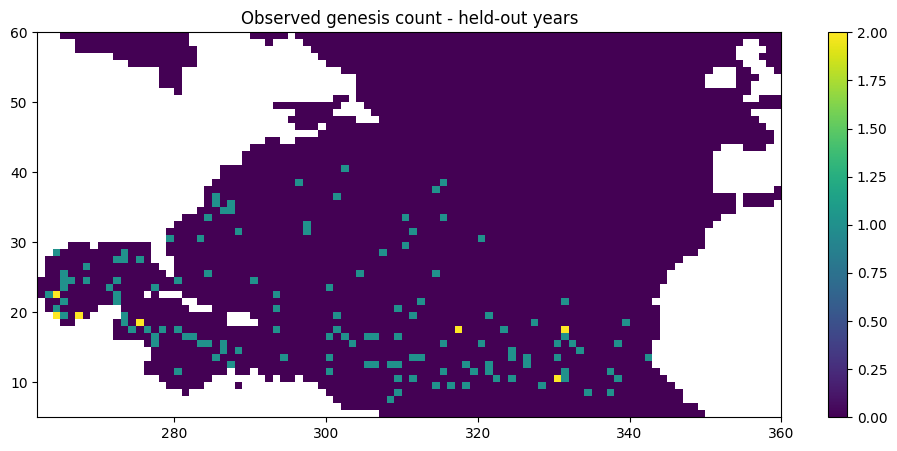

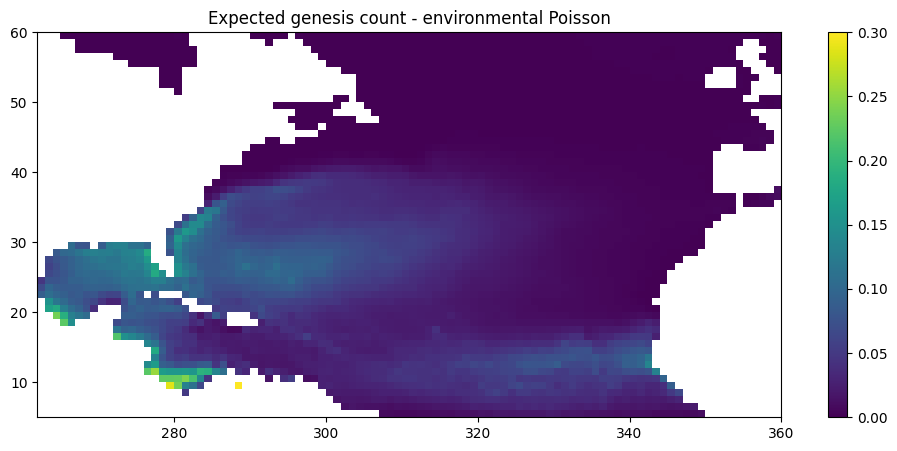

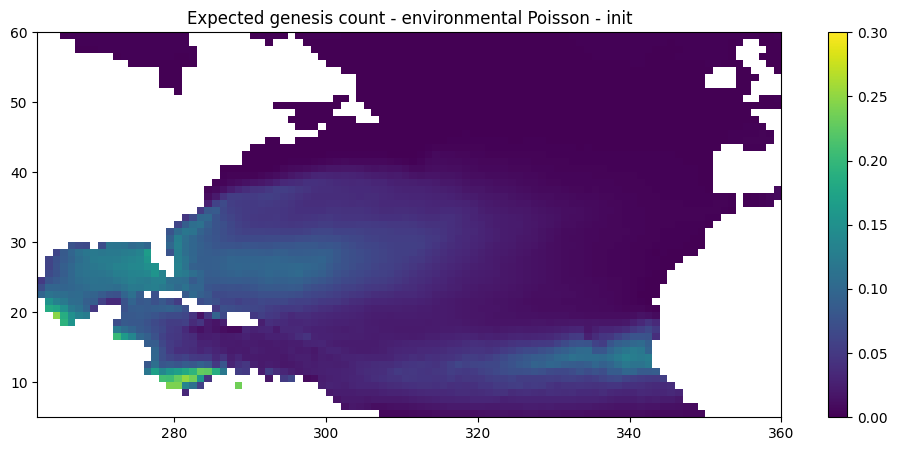

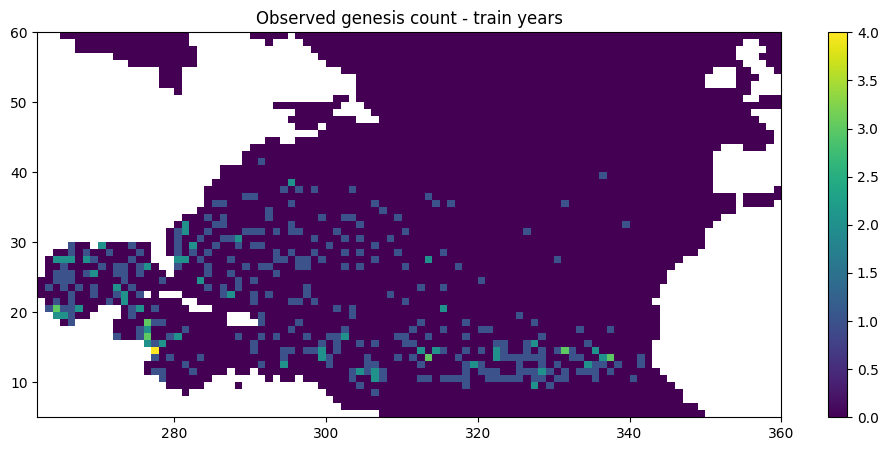

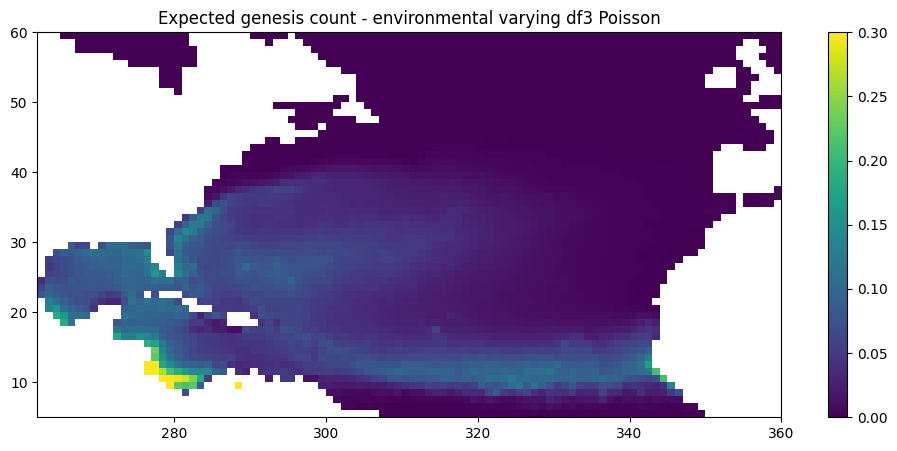

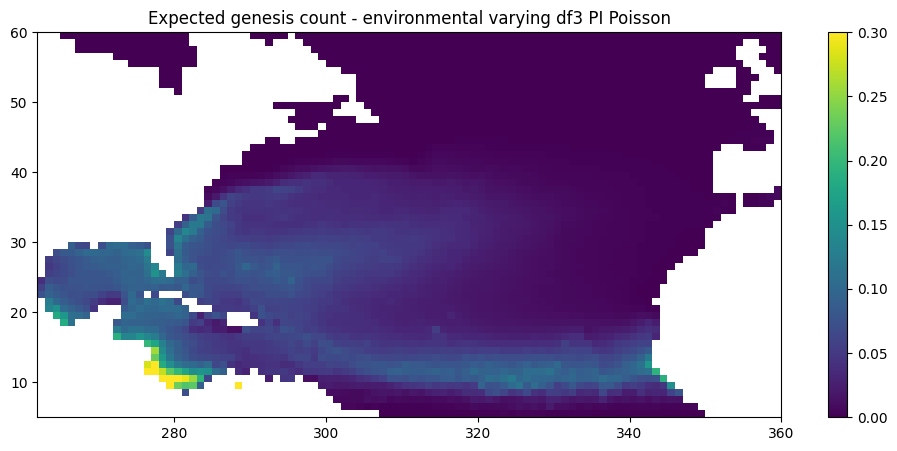

In [51]:
def spatial_summary(df: pd.DataFrame, mu_col: str) -> pd.DataFrame:
    return (
        df.groupby(["latitude", "longitude"], as_index=False)
        .agg(
            observed=("genesis_count", "sum"),
            expected=(mu_col, "sum"),
        )
    )


spatial = spatial_summary(test, "mu_m2")
spatial_init = spatial_summary(test, "mu_m1")
spatial_bis = spatial_summary(train, "genesis_count")
spatial_ter = spatial_summary(test_eta, "genesis_count")

spatial_quat = spatial_summary(test_eta, "mu_m_varying")
spatial_cinq = spatial_summary(test_eta, "mu_m_pi_varying")

obs = spatial.pivot(index="latitude", columns="longitude", values="observed")
obs2 = spatial_bis.pivot(index="latitude", columns="longitude", values="observed")
exp = spatial.pivot(index="latitude", columns="longitude", values="expected")
exp_init = spatial_init.pivot(index="latitude", columns="longitude", values="expected")
vary = spatial_quat.pivot(index="latitude", columns="longitude", values="expected")
vary2 = spatial_cinq.pivot(index="latitude", columns="longitude", values="expected")

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.pcolormesh(obs.columns, obs.index, obs.values, shading="auto")
ax.set_title("Observed genesis count - held-out years")
plt.colorbar(im, ax=ax)
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.pcolormesh(exp.columns, exp.index, exp.values, shading="auto", vmax=0.3, vmin=0)
ax.set_title("Expected genesis count - environmental Poisson")
plt.colorbar(im, ax=ax)
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.pcolormesh(
    exp_init.columns, exp_init.index, exp_init.values, shading="auto", vmax=0.3, vmin=0
)
ax.set_title("Expected genesis count - environmental Poisson - init")
plt.colorbar(im, ax=ax)
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.pcolormesh(obs2.columns, obs2.index, obs2.values, shading="auto")
ax.set_title("Observed genesis count - train years")
plt.colorbar(im, ax=ax)
plt.show()


fig, ax = plt.subplots(figsize=(12, 5))
im = ax.pcolormesh(vary.columns, vary.index, vary.values, shading="auto", vmax=0.3, vmin=0)
ax.set_title("Expected genesis count - environmental varying df3 Poisson")
plt.colorbar(im, ax=ax)
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.pcolormesh(
    vary2.columns, vary2.index, vary2.values, shading="auto", vmax=0.3, vmin=0
)
ax.set_title("Expected genesis count - environmental varying df3 PI Poisson")
plt.colorbar(im, ax=ax)
plt.show()


In [ ]:
historical = (
    pd.concat(
        [train_soft, test_soft],
        ignore_index=True,
    )
    .sort_values(["year", "month", "latitude", "longitude"])
    .reset_index(drop=True)
)


## 15. Fit final historical model

Only after the model form has been selected using blocked/rolling validation should the operational model be refit on the full historical period.

Do not use held-out test years to choose predictors and then report the same years as untouched validation.

In [ ]:
final_scaler = fit_standardizer(model_df, FEATURES)
final_df = apply_standardizer(model_df, final_scaler)

_, final_model = fit_poisson_models(final_df)

## 16. Forecast inference from one SEAS5 member/month

Prepare the forecast environment on exactly the same 1° grid and with the same variable definitions as ERA5.

The model produces `mu_cell`, the expected number of genesis events in each eligible cell for that forecast month.

Then:

\[
\Lambda=\sum_i \mu_i,
\qquad
N\sim Pois(\Lambda),
\qquad
p_i=\mu_i/\Lambda.
\]

In [ ]:
def build_forecast_table(
    env_month_1deg: xr.Dataset,
    coarse_exposure: xr.Dataset,
    valid_month: pd.Timestamp,
    cfg: GenesisConfig,
    scaler: dict,
) -> pd.DataFrame:
    df = (
        env_month_1deg[FEATURES]
        .to_dataframe()
        .reset_index()
    )

    exp_df = (
        coarse_exposure[
            ["eligible_area_km2", "eligible_fraction"]
        ]
        .to_dataframe()
        .reset_index()
    )

    df = df.merge(exp_df, on=["lat", "lon"], how="left")

    valid_month = pd.Timestamp(valid_month).to_period("M").to_timestamp()
    df["time"] = valid_month
    df["year"] = valid_month.year
    df["month"] = valid_month.month

    days = valid_month.days_in_month
    df["exposure"] = (
        (df["eligible_area_km2"] / cfg.area_unit_km2)
        * (days / cfg.reference_month_days)
    )

    valid = (
        (df["eligible_fraction"] >= MIN_ELIGIBLE_FRACTION)
        & (df["exposure"] > 0)
        & np.isfinite(df[FEATURES]).all(axis=1)
    )

    df = df.loc[valid].copy()
    df["log_exposure"] = np.log(df["exposure"])
    df = apply_standardizer(df, scaler)
    return df

# forecast_df = build_forecast_table(
#     seas5_member_month_1deg,
#     coarse_exposure,
#     valid_month="2026-08-01",
#     cfg=CFG,
#     scaler=final_scaler,
# )

# forecast_df["mu_cell"] = final_model.predict(
#     forecast_df,
#     offset=forecast_df["log_exposure"],
# )

## 17. Draw the monthly count and 1° genesis cells

This is the single replacement for both the current basin-frequency draw and the GPI/empirical genesis-map draw.

In [ ]:
def sample_genesis_cells(
    forecast_df: pd.DataFrame,
    rng: np.random.Generator,
    mu_col: str = "mu_cell",
) -> tuple[int, pd.DataFrame]:
    mu = np.clip(forecast_df[mu_col].to_numpy(dtype=float), 0, None)
    Lambda = mu.sum()

    if not np.isfinite(Lambda) or Lambda < 0:
        raise ValueError(f"Invalid integrated genesis rate: {Lambda}")

    n = int(rng.poisson(Lambda))
    if n == 0:
        return 0, forecast_df.iloc[0:0].copy()

    p = mu / Lambda
    chosen = rng.choice(len(forecast_df), size=n, replace=True, p=p)

    return n, forecast_df.iloc[chosen].copy().reset_index(drop=True)

# rng = np.random.default_rng(20260923)
# n, selected_cells = sample_genesis_cells(forecast_df, rng)
# print("Simulated genesis count:", n)

## 18. Uniform 0.1° ocean-constrained downscaling within a selected 1° cell

Your proposed simple downscaling is appropriate for V1.

The only change I would insist on is:

**uniform conditional on eligible ocean**, not uniform over the whole 1° square.

Procedure:

1. identify all eligible 0.1° subcells inside the selected 1° cell;
2. choose one with probability proportional to its spherical area;
3. either use its centre as the 0.1° genesis location, or jitter uniformly within the 0.1° cell.

The optional jitter below is truly area-uniform on the sphere by sampling uniformly in `sin(latitude)`.

In [ ]:
def sample_point_in_selected_cell(
    coarse_lat: float,
    coarse_lon: float,
    fine_mask: xr.Dataset,
    cfg: GenesisConfig,
    rng: np.random.Generator,
    jitter_within_fine_cell: bool = False,
) -> tuple[float, float]:
    r = int(round(cfg.coarse_res / cfg.fine_res))

    ilat = int(round((coarse_lat - (cfg.lat_min + cfg.coarse_res / 2)) / cfg.coarse_res))
    ilon = int(round((coarse_lon - (cfg.lon_min + cfg.coarse_res / 2)) / cfg.coarse_res))

    ys = slice(ilat * r, (ilat + 1) * r)
    xs = slice(ilon * r, (ilon + 1) * r)

    eligible = fine_mask["eligible"].values[ys, xs]
    area = fine_mask["fine_area_km2"].values[ys, xs]

    candidates = np.argwhere(eligible)
    if len(candidates) == 0:
        raise RuntimeError(
            f"Selected coarse cell ({coarse_lat}, {coarse_lon}) "
            "contains no eligible fine ocean cells."
        )

    weights = area[eligible].astype(float)
    weights /= weights.sum()

    k = rng.choice(len(candidates), p=weights)
    jy, jx = candidates[k]

    fine_lat_values = fine_mask["fine_lat"].values[ys]
    fine_lon_values = fine_mask["fine_lon"].values[xs]

    lat_c = float(fine_lat_values[jy])
    lon_c = float(fine_lon_values[jx])

    if not jitter_within_fine_cell:
        # Exact 0.1° output on fine-cell centres.
        return lat_c, lon_c

    half = cfg.fine_res / 2

    lat_lo = np.deg2rad(lat_c - half)
    lat_hi = np.deg2rad(lat_c + half)

    # Equal-area latitude draw on a sphere.
    sin_lat = rng.uniform(np.sin(lat_lo), np.sin(lat_hi))
    lat_out = np.rad2deg(np.arcsin(sin_lat))
    lon_out = rng.uniform(lon_c - half, lon_c + half)

    return float(lat_out), float(lon_out)


def downscale_selected_cells(
    selected_cells: pd.DataFrame,
    fine_mask: xr.Dataset,
    cfg: GenesisConfig,
    rng: np.random.Generator,
) -> pd.DataFrame:
    out = selected_cells.copy()
    points = [
        sample_point_in_selected_cell(
            row.lat,
            row.lon,
            fine_mask=fine_mask,
            cfg=cfg,
            rng=rng,
            jitter_within_fine_cell=False,
        )
        for row in out.itertuples()
    ]

    if points:
        out["genesis_lat"] = [p[0] for p in points]
        out["genesis_lon"] = [p[1] for p in points]
    else:
        out["genesis_lat"] = []
        out["genesis_lon"] = []

    return out

# simulated_genesis = downscale_selected_cells(
#     selected_cells,
#     fine_mask,
#     CFG,
#     rng,
# )

## 19. One complete forecast-month simulation function

In [ ]:
def simulate_forecast_month(
    env_month_1deg: xr.Dataset,
    valid_month,
    final_model,
    scaler,
    coarse_exposure: xr.Dataset,
    fine_mask: xr.Dataset,
    cfg: GenesisConfig,
    rng: np.random.Generator,
) -> pd.DataFrame:
    forecast_df = build_forecast_table(
        env_month_1deg=env_month_1deg,
        coarse_exposure=coarse_exposure,
        valid_month=pd.Timestamp(valid_month),
        cfg=cfg,
        scaler=scaler,
    )

    forecast_df["mu_cell"] = final_model.predict(
        forecast_df,
        offset=forecast_df["log_exposure"],
    )

    _, selected = sample_genesis_cells(
        forecast_df,
        rng=rng,
        mu_col="mu_cell",
    )

    return downscale_selected_cells(
        selected,
        fine_mask=fine_mask,
        cfg=cfg,
        rng=rng,
    )

## 20. Sensitivity experiments before accepting the model

The following are more important than adding a complicated spatial random field.

### Resolution
Repeat the complete fit at:

- 0.5°
- 1°
- 2°

and compare held-out:

- basin-month Poisson log score;
- spatial cell log likelihood;
- integrated annual count bias;
- genesis density maps;
- downstream track/landfall differences.

The expectation is that 1° and 2° will often be close. Use the experiment to justify the choice rather than assuming it.

### Environmental specification
Compare at least:

- M0: month only;
- M1: month + PI + RH + VWS + absolute vorticity;
- M2: M1 with saturating/nonlinear vorticity;
- M3: selected GAM/spline effects if M2 leaves strong nonlinear residuals;
- current phase-frequency + GPI-MIX baseline.

### Distribution
Start with Poisson. Escalate only if held-out aggregate counts show persistent conditional overdispersion.

### Validation
Use blocked or rolling years. Never choose the model from random cell-row cross-validation.

## 21. Recommended next notebook

Once this linear Poisson version is stable, the next notebook should answer only one question:

**Do nonlinear environmental response functions materially improve held-out count and spatial-genesis skill?**

That notebook can compare:

- linear GLM;
- capped/saturating vorticity;
- physically motivated transforms;
- GAM splines;
- PI vs relative SST vs ventilated PI.

Do not add clustering, negative-binomial dispersion, climate indices, or a latent process until the basic environmental rate model has been validated.